# Experimentos de classificação

Este notebook reúne o código detalhado dos experimentos adicionais (protocolo B).
O [notebook principal](classification_perfil_investimento.ipynb) preserva o desenvolvimento
iniciado pela equipe e apresenta um resumo destes resultados.

Aqui usamos células Python comuns, com variáveis como `X_train`, `model`, `history`
e `grid_results`. Execute este notebook em uma sessão própria, em ordem; ele não depende
de executar outro notebook nem de arquivos `.py` do projeto.

A preparação abaixo repete somente as etapas do [EDA](../eda/EDA_perfil_investimento.ipynb)
necessárias à classificação. As análises exploratórias permanecem no EDA.
Os experimentos e as saídas já foram registrados. Executar todas as células refaz os treinos
e a busca; a avaliação final reutiliza as previsões salvas quando o protocolo coincide.
Para apenas consultar os resultados, use o resumo do notebook principal.

**Histórico dos critérios:** o protocolo B adotou ganho de 10% antes dos treinos;
o desenvolvimento original (protocolo A) adotou 15%. São procedimentos diferentes,
com splits e regras distintos. Ambos os critérios foram mantidos e nenhum foi atingido.
Esta organização não representa uma nova avaliação independente do conjunto de teste.


## Preparação dos dados

Mesmas fontes, construção das features e divisão estratificada 80/20 do EDA.

In [ ]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
sns.set_theme(style="whitegrid")

In [ ]:
PROJECT_ROOT = next(
    (pasta for pasta in [Path.cwd(), *Path.cwd().parents]
     if (pasta / "mkdocs.yml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Abra o notebook dentro do repositório ann-dl.")

DATA_DIR = PROJECT_ROOT / "Dados"
ACCOUNT_PATH = DATA_DIR / "account.json"
POLICY_PATH = DATA_DIR / "clientes_investment_policy.json"
WALLET_PATH = DATA_DIR / "clientes_wallet_distribution.json"

for arquivo in [ACCOUNT_PATH, POLICY_PATH, WALLET_PATH]:
    if not arquivo.is_file():
        raise FileNotFoundError(f"Arquivo de dados não encontrado: {arquivo}")


In [ ]:
def stream_json_array(path, chunk_size=1024 * 1024):
    """
    Leitura incremental de um JSON cujo nível superior é uma lista.
    Evita carregar a wallet inteira na memória.
    """
    decoder = json.JSONDecoder()

    with open(path, "r", encoding="utf-8") as arquivo:
        buffer = ""
        iniciou_lista = False
        fim_arquivo = False

        while True:
            if not fim_arquivo and len(buffer) < chunk_size:
                trecho = arquivo.read(chunk_size)
                if trecho:
                    buffer += trecho
                else:
                    fim_arquivo = True

            buffer = buffer.lstrip()

            if not iniciou_lista:
                if not buffer:
                    if fim_arquivo:
                        return
                    continue

                if buffer[0] != "[":
                    raise ValueError(
                        "O JSON de nível superior deve ser uma lista."
                    )

                buffer = buffer[1:]
                iniciou_lista = True
                continue

            if buffer.startswith(","):
                buffer = buffer[1:].lstrip()

            if buffer.startswith("]"):
                return

            if not buffer:
                if fim_arquivo:
                    return
                continue

            try:
                item, indice = decoder.raw_decode(buffer)
            except json.JSONDecodeError:
                if fim_arquivo:
                    raise
                trecho = arquivo.read(chunk_size)
                if trecho:
                    buffer += trecho
                else:
                    fim_arquivo = True
                continue

            buffer = buffer[indice:]
            yield item

In [ ]:
BUCKETS = {
    "stocks": "pct_stocks",
    "fixedIncome": "pct_fixed_income",
    "repo": "pct_repo",
    "investimentFund": "pct_investment_fund",
    "balance": "pct_cash",
    "options": "pct_options",
    "treasure": "pct_treasure",
    "future": "pct_future",
    "privatePension": "pct_private_pension",
    "term": "pct_term",
    "coe": "pct_coe",
    "realEstate": "pct_real_estate",
    "structruedProduct": "pct_structured_product",
}


def extrair_percentual(bucket):
    """
    Recupera o percentual de um bucket da wallet.
    """
    if not isinstance(bucket, dict):
        return 0.0

    percentual = bucket.get("percent")

    if percentual is None:
        percentual = bucket.get("percentDetail")

    if percentual is None:
        return 0.0

    try:
        return float(percentual)
    except (TypeError, ValueError):
        return 0.0

In [ ]:
def carregar_wallet(path):
    linhas = []

    for item in stream_json_array(path):
        client = item.get("client")
        response = item.get("response") or {}

        sucesso = bool(
            response.get("success", False)
        )

        output = response.get("output") or {}

        linha = {
            "accountCode": str(client),
            "wallet_ok": sucesso,
            "wallet_updated_at": output.get("updatedAt"),
        }

        percentuais = []

        for bucket_original, feature in BUCKETS.items():
            if sucesso:
                percentual = extrair_percentual(
                    output.get(bucket_original)
                )
            else:
                percentual = np.nan

            linha[feature] = percentual
            percentuais.append(percentual)

        if sucesso:
            linha["num_active_buckets"] = int(
                sum(p > 0 for p in percentuais)
            )
            linha["max_bucket_pct"] = max(percentuais)
            linha["pct_sum_selected"] = sum(percentuais)
            linha["empty_wallet"] = bool(
                all(p == 0 for p in percentuais)
            )
        else:
            linha["num_active_buckets"] = np.nan
            linha["max_bucket_pct"] = np.nan
            linha["pct_sum_selected"] = np.nan
            linha["empty_wallet"] = False

        linhas.append(linha)

    return pd.DataFrame(linhas)

In [ ]:
wallet_raw = carregar_wallet(
    WALLET_PATH
)

print(
    "Dimensão da wallet:",
    wallet_raw.shape
)

display(
    wallet_raw.head()
)

Dimensão da wallet: (21934, 20)


,accountCode,wallet_ok,wallet_updated_at,pct_stocks,pct_fixed_income,pct_repo,pct_investment_fund,pct_cash,pct_options,pct_treasure,pct_future,pct_private_pension,pct_term,pct_coe,pct_real_estate,pct_structured_product,num_active_buckets,max_bucket_pct,pct_sum_selected,empty_wallet
0,463600,True,2026-08-26T10:04:17.977131,0.0,12.6,0.0,37.4,0.32,0.0,0.0,0.0,49.7,0.0,0.0,0.0,0.0,4,49.7,100.02,False
1,4811009,True,2026-08-26T10:12:29.8496439,0.0,36.6,0.0,43.1,1.45,0.0,0.0,0.0,16.2,0.0,0.0,2.6,0.0,5,43.1,99.95,False
2,6930035,True,2026-08-26T10:14:20.9994076,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.00,True
3,2008978,True,2026-08-26T10:10:03.7624948,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.00,True
4,2628555,True,2026-08-26T10:08:36.2641493,0.0,0.0,0.0,99.9,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2,99.9,100.02,False


In [ ]:
with open(
    POLICY_PATH,
    "r",
    encoding="utf-8"
) as arquivo:
    policy_json = json.load(arquivo)

classes_validas = {
    "Conservadora",
    "Moderada",
    "Sofisticada",
}

linhas_policy = []

for account_code, objeto in policy_json.items():
    output = (
        objeto.get("output")
        if objeto
        else None
    ) or {}

    adherence = (
        output.get("adherence")
        or {}
    )

    linhas_policy.append({
        "accountCode": str(account_code),
        "investmentPolicy": adherence.get(
            "investmentPolicy"
        ),
    })

policy_raw = pd.DataFrame(linhas_policy)

del policy_json

print(
    "Dimensão da policy:",
    policy_raw.shape
)

display(
    policy_raw["investmentPolicy"]
    .value_counts(dropna=False)
    .to_frame("n")
)

Dimensão da policy: (21308, 2)


,n
investmentPolicy,
Moderada,10032
Conservadora,8208
NaN,2303
Sofisticada,765


In [ ]:
with open(
    ACCOUNT_PATH,
    "r",
    encoding="utf-8"
) as arquivo:
    account_json = json.load(arquivo)

account_raw = pd.DataFrame(
    account_json.get(
        "data",
        []
    )
)

del account_json

account_raw[
    "accountCode"
] = (
    account_raw[
        "accountCode"
    ]
    .astype(str)
)

print(
    "Dimensão do cadastro:",
    account_raw.shape
)

display(
    account_raw.head()
)

Dimensão do cadastro: (23352, 20)


,dimAccountCode,accountCode,registerDate,personType,maritalStatus,activity,dscSuitability,realStateValue,movableAssetsValue,incomeValue,financialApplicationsValue,othersValue,qualifiedInvestorTerm,professionalTerm,startValidityDate,endValidityDate,currentRegisterIndicator,id,lastUpdate,availableData
0,79380941,7277174,2021-11-24T00:00:00,J,NÃO INFORMADO,SERVICOS AUXILIARES DIVERSOS,CONSERVADOR,0.0,0.0,0.0,0.0,0.0,N,N,2025-08-26T00:00:00,9999-12-31T00:00:00,1,28,2026-08-28T14:59:01.387,True
1,88813311,7616952,2022-01-07T00:00:00,F,SOLTEIRO(A),AGENTE ADMINISTRATIVO,MODERADO,1.0,1.0,4001.0,30000.0,0.0,N,N,2025-11-04T00:00:00,9999-12-31T00:00:00,1,29,2026-08-28T14:59:01.387,True
2,70123546,4603613,2020-11-12T00:00:00,F,SOLTEIRO(A),JORNALISTA,AGRESSIVO,2000000.0,50000.0,8001.0,5000000.0,0.0,S,N,2025-04-14T00:00:00,9999-12-31T00:00:00,1,101,2026-08-28T14:59:01.387,True
3,74403982,3168449,2019-03-24T00:00:00,F,CASADO(A) COM BRASILEIRO(A) NATO(A),ADVOGADO,AGRESSIVO,0.0,0.0,3000.0,200000.0,0.0,N,N,2025-06-03T00:00:00,9999-12-31T00:00:00,1,102,2026-08-28T14:59:01.387,True
4,90577710,2438610,2018-02-15T00:00:00,F,SOLTEIRO(A),EMPRESARIO,MODERADO,0.0,0.0,25000.0,1000000.0,0.0,S,N,2025-11-04T00:00:00,9999-12-31T00:00:00,1,103,2026-08-28T14:59:01.387,True


In [ ]:
account = account_raw.copy()

if "currentRegisterIndicator" in account.columns:
    atuais = (
        account[
            "currentRegisterIndicator"
        ] == 1
    )

    if atuais.any():
        account = account[
            atuais
        ].copy()

if "lastUpdate" in account.columns:
    account[
        "lastUpdate"
    ] = pd.to_datetime(
        account[
            "lastUpdate"
        ],
        errors="coerce"
    )

    account = account.sort_values(
        "lastUpdate"
    )

account = (
    account
    .drop_duplicates(
        "accountCode",
        keep="last"
    )
    .copy()
)

print(
    "Cadastro consolidado:",
    account.shape
)

Cadastro consolidado: (23352, 20)


In [ ]:
policy = (
    policy_raw[
        policy_raw[
            "investmentPolicy"
        ].isin(
            classes_validas
        )
    ]
    .drop_duplicates(
        "accountCode",
        keep="last"
    )
    .copy()
)

wallet = (
    wallet_raw[
        wallet_raw[
            "wallet_ok"
        ]
    ]
    .copy()
)

wallet[
    "wallet_updated_at"
] = pd.to_datetime(
    wallet[
        "wallet_updated_at"
    ],
    errors="coerce"
)

In [ ]:
df = (
    wallet
    .merge(
        policy[
            [
                "accountCode",
                "investmentPolicy",
            ]
        ],
        on="accountCode",
        how="inner",
    )
    .merge(
        account,
        on="accountCode",
        how="left",
    )
)

print(
    "Dataset final:",
    df.shape
)

wallet_sem_policy = (
    ~wallet[
        "accountCode"
    ].isin(
        policy[
            "accountCode"
        ]
    )
).sum()

print(
    "Contas da wallet sem policy válida:",
    int(wallet_sem_policy)
)

Dataset final: (19004, 40)
Contas da wallet sem policy válida: 2930


In [ ]:
percentage_features = list(
    BUCKETS.values()
)

numeric_candidates = (
    percentage_features
    + [
        "num_active_buckets",
        "max_bucket_pct",
    ]
)

categorical_candidates = [
    "personType"
]

constant_features = [
    coluna
    for coluna
    in (
        numeric_candidates
        + categorical_candidates
    )
    if (
        df[
            coluna
        ]
        .nunique(
            dropna=False
        )
        <= 1
    )
]

target = "investmentPolicy"

numeric_features = [
    coluna
    for coluna in numeric_candidates
    if coluna not in constant_features
]

categorical_features = [
    coluna
    for coluna in categorical_candidates
    if coluna not in constant_features
]

feature_cols = (
    numeric_features
    + categorical_features
)

print(
    "Features constantes:",
    constant_features
)
print(
    "Features numéricas:",
    numeric_features
)
print(
    "Features categóricas:",
    categorical_features
)

Features constantes:

 ['pct_future']
Features numéricas: ['pct_stocks', 'pct_fixed_income', 'pct_repo', 'pct_investment_fund', 'pct_cash', 'pct_options', 'pct_treasure', 'pct_private_pension', 'pct_term', 'pct_coe', 'pct_real_estate', 'pct_structured_product', 'num_active_buckets', 'max_bucket_pct']
Features categóricas: ['personType']


In [ ]:
X = (
    df[
        feature_cols
    ]
    .copy()
)

y = (
    df[
        target
    ]
    .copy()
)

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y,
    )
)

print(
    "Treino:",
    X_train.shape
)

print(
    "Teste:",
    X_test.shape
)

Treino: (15203, 15)
Teste: (3801, 15)


In [ ]:
def build_preprocessor(
    numeric_features,
    categorical_features,
):
    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            ),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            ),
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_pipeline,
                numeric_features,
            ),
            (
                "cat",
                categorical_pipeline,
                categorical_features,
            ),
        ]
    )

    return preprocessor

In [ ]:
preprocess = build_preprocessor(
    numeric_features,
    categorical_features,
)

# FIT exclusivamente no treino.
X_train_t = (
    preprocess.fit_transform(
        X_train
    )
)

# Teste recebe apenas transform.
X_test_t = (
    preprocess.transform(
        X_test
    )
)

feature_names = (
    preprocess
    .get_feature_names_out()
)

print(
    "Shape treino original:",
    X_train.shape
)

print(
    "Shape treino transformado:",
    X_train_t.shape
)

print(
    "Shape teste transformado:",
    X_test_t.shape
)

Shape treino original: (15203, 15)
Shape treino transformado: (15203, 16)
Shape teste transformado: (3801, 16)


## 0. Ponto de partida

### 0.1. Métrica principal e critério definidos antes dos treinos

A métrica principal será o **F1 macro**, média simples do F1 das três classes.
Cada classe terá o mesmo peso na avaliação, mesmo com `Sofisticada` representando
somente 4,03% dos exemplos observados no EDA. Também acompanharemos precisão,
recall e F1 por classe.

O critério prévio é obter **F1 macro na validação pelo menos 10% maior que o do
melhor baseline**, escolhido entre o trivial e o linear na mesma validação:

`F1_macro_MLP >= 1.10 * F1_macro_melhor_baseline`

O ganho é relativo: se o melhor baseline tiver F1 macro de 0,50, a meta será 0,55.
A margem de 10% é uma meta do projeto para justificar a complexidade adicional da MLP.
As configurações serão escolhidas pela validação. A avaliação final no teste
será realizada depois dessas decisões, sem novos ajustes orientados pelo teste.


In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
VALIDATION_SIZE = 0.25  # Fração dos 80% de treino externo do EDA.
SUCCESS_FACTOR = 1.10
CLASS_LABELS = ["Conservadora", "Moderada", "Sofisticada"]

np.random.seed(RANDOM_STATE)
# O EDA suprime avisos; manter os de convergência visíveis nesta etapa.
warnings.simplefilter("always", ConvergenceWarning)
pd.set_option("display.max_columns", 100)

# Usar explicitamente todas as classes no cálculo da métrica.
def f1_macro(y_true, y_pred):
    return f1_score(
        y_true,
        y_pred,
        labels=CLASS_LABELS,
        average="macro",
        zero_division=0,
    )

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mkdocs.yml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Abra o notebook dentro do repositório ann-dl.")


### 0.2. Estado herdado do EDA

O EDA já construiu `df`, `X`, `y`, as listas de features e o split 80/20 com
semente 42. Guardamos os conjuntos e o pré-processamento do EDA com o sufixo
`_eda` antes de separar a validação. As células de validação e de treinamento
abaixo usam esses conjuntos preservados.

O pré-processador do EDA foi ajustado em todo o treino externo, por isso será
criado outro para aprender estatísticas somente no treino interno. A matriz de
teste transformada no EDA fica identificada como `X_test_eda_t`; qualquer
avaliação final da classificação deverá usar a transformação do modelo final.


In [ ]:
X_train_eda = X_train.copy()
y_train_eda = y_train.copy()
preprocess_eda = preprocess
X_train_eda_t = X_train_t
X_test_eda_t = X_test_t
del X_test_t

print("Treino externo herdado do EDA:", X_train_eda.shape)
print("Teste externo preservado:", X_test.shape)


Treino externo herdado do EDA: (15203, 15)
Teste externo preservado: (3801, 15)


### 0.3. Validação a partir do split do EDA

Aproveitamos o split estratificado já executado no EDA: 80% treino externo e
20% teste, com semente 42. Dividimos apenas o treino externo, destinando 25%
dele à validação, também com estratificação e semente 42. No total, são cerca de
60% para ajuste, 20% para validação e 20% para teste.

Com as 19.004 contas registradas no EDA, são esperadas 11.402 linhas para ajuste,
3.801 para validação e 3.801 para teste. Os totais efetivos aparecem na célula.
Usamos `X_train_eda` para o treino externo e `X_train` para o treino interno.
O teste fica reservado para a avaliação final.


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_eda,
    y_train_eda,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train_eda,
)

split_summary = pd.DataFrame({
    "conjunto": ["Treino", "Validação", "Teste reservado"],
    "linhas": [len(X_train), len(X_val), len(X_test)],
})
split_summary["percentual_total"] = 100 * split_summary["linhas"] / len(X)
display(split_summary.round(2))

# Conferir o equilíbrio de classes somente nos conjuntos de desenvolvimento.
display(pd.DataFrame({
    "treino_n": y_train.value_counts(),
    "treino_%": 100 * y_train.value_counts(normalize=True),
    "validacao_n": y_val.value_counts(),
    "validacao_%": 100 * y_val.value_counts(normalize=True),
}).reindex(CLASS_LABELS).round(2))


,conjunto,linhas,percentual_total
0,Treino,11402,60.0
1,Validação,3801,20.0
2,Teste reservado,3801,20.0


,treino_n,treino_%,validacao_n,validacao_%
investmentPolicy,,,,
Conservadora,4924,43.19,1642,43.20
Moderada,6019,52.79,2006,52.78
Sofisticada,459,4.03,153,4.03


### 0.4. Pré-processamento ajustado no treino interno

Reutilizamos `build_preprocessor`, já definida na Parte 1 deste notebook: imputação pela
mediana e escala padrão para numéricas; imputação pela moda e one-hot para
`personType`. Um novo pré-processador aprende as estatísticas somente nas linhas
de treino interno. A validação recebe apenas `transform`.

O teste será transformado na etapa final com o pré-processador correspondente
ao modelo final. Esses dados de validação serão usados nos baselines, na busca
de configurações e na parada antecipada.


In [ ]:
preprocess = build_preprocessor(
    numeric_features,
    categorical_features,
)
X_train_t = preprocess.fit_transform(X_train)
X_val_t = preprocess.transform(X_val)
feature_names = preprocess.get_feature_names_out()

print("Treino após pré-processamento:", X_train_t.shape)
print("Validação após pré-processamento:", X_val_t.shape)


Treino após pré-processamento: (11402, 16)
Validação após pré-processamento: (3801, 16)


## 1. Baselines

### 1.1. Modelos de referência

O **DummyClassifier com `strategy="most_frequent"`** sempre prevê a classe mais
frequente no treino. Ele mostra quanto do resultado vem apenas da distribuição
das classes. Como ignora as entradas, pode apresentar acurácia aparentemente
boa e F1 nulo para as classes que nunca prevê.

A **regressão logística multiclasse** testa se fronteiras lineares nas mesmas
features já são suficientes para explicar o alvo. Usamos `C=1.0` (regularização
L2), `solver="lbfgs"` e até 3.000 iterações para favorecer a convergência.
O aumento do limite de iterações é uma condição de otimização, sem busca de
hiperparâmetros nesta etapa. Se houver aviso de convergência, ele deve ser
resolvido antes de interpretar os números.

Comparamos duas versões desse baseline linear, com `class_weight=None` e
`class_weight="balanced"`. A versão balanceada aumenta o peso das classes raras
na perda, usando somente suas frequências no treino. Ela pode melhorar o F1
macro e o recall de `Sofisticada`, com possível redução da acurácia.

Os três modelos usam as mesmas linhas de treino e validação e o mesmo tipo de
pré-processamento do EDA. Cada pipeline recebe uma cópia nova do pré-processador,
ajustada apenas no treino interno. A escolha do melhor baseline usa F1 macro na
validação, sem consultar o teste.


In [20]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline

baseline_estimators = {
    "Dummy majoritário": DummyClassifier(
        strategy="most_frequent",
        random_state=RANDOM_STATE,
    ),
    "Logística": LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=3000,
        class_weight=None,
        random_state=RANDOM_STATE,
    ),
    "Logística balanceada": LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=3000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

baseline_models = {
    nome: Pipeline([
        ("preprocess", clone(preprocess)),
        ("model", estimator),
    ])
    for nome, estimator in baseline_estimators.items()
}


In [21]:
baseline_rows = []
baseline_reports = {}
baseline_predictions_val = {}

for nome, model in baseline_models.items():
    model.fit(X_train, y_train)
    pred_train = model.predict(X_train)
    pred_val = model.predict(X_val)
    baseline_predictions_val[nome] = pred_val

    report = classification_report(
        y_val,
        pred_val,
        labels=CLASS_LABELS,
        output_dict=True,
        zero_division=0,
    )
    baseline_reports[nome] = (
        pd.DataFrame(report)
        .T.loc[CLASS_LABELS + ["macro avg", "weighted avg"]]
        .rename(columns={
            "precision": "precisao",
            "recall": "recall",
            "f1-score": "f1",
            "support": "n_exemplos",
        })
    )
    train_f1 = f1_macro(y_train, pred_train)
    val_f1 = f1_macro(y_val, pred_val)
    baseline_rows.append({
        "modelo": nome,
        "f1_macro_treino": train_f1,
        "f1_macro_val": val_f1,
        "diferenca_treino_val": train_f1 - val_f1,
        "acuracia_val": accuracy_score(y_val, pred_val),
        "recall_sofisticada_val": report["Sofisticada"]["recall"],
        "f1_sofisticada_val": report["Sofisticada"]["f1-score"],
    })

baseline_results = (
    pd.DataFrame(baseline_rows)
    .set_index("modelo")
    .sort_values("f1_macro_val", ascending=False, kind="stable")
)
display(baseline_results.round(4))

print("Métricas por classe na validação:")
display(pd.concat(baseline_reports, names=["modelo", "classe"]).round(4))


,f1_macro_treino,f1_macro_val,diferenca_treino_val,acuracia_val,recall_sofisticada_val,f1_sofisticada_val
modelo,,,,,,
Logística,0.3509,0.3550,-0.0042,0.5577,0.0000,0.0000
Logística balanceada,0.3195,0.3102,0.0093,0.4070,0.3268,0.0934
Dummy majoritário,0.2303,0.2303,0.0000,0.5278,0.0000,0.0000


Métricas por classe na validação:


precisao  recall      f1  n_exemplos
modelo               classe                                            
Dummy majoritário    Conservadora    0.0000  0.0000  0.0000      1642.0
                     Moderada        0.5278  1.0000  0.6909      2006.0
                     Sofisticada     0.0000  0.0000  0.0000       153.0
                     macro avg       0.1759  0.3333  0.2303      3801.0
                     weighted avg    0.2785  0.5278  0.3646      3801.0
Logística            Conservadora    0.5436  0.3264  0.4079      1642.0
                     Moderada        0.5627  0.7896  0.6571      2006.0
                     Sofisticada     0.0000  0.0000  0.0000       153.0
                     macro avg       0.3688  0.3720  0.3550      3801.0
                     weighted avg    0.5318  0.5577  0.5230      3801.0
Logística balanceada Conservadora    0.5062  0.7259  0.5964      1642.0
                     Moderada        0.5777  0.1520  0.2407      2006.0
                     Sofisticada     0.0545  0.3268  0.0934       153.0
                     macro avg       0.3794  0.4016  0.3102      3801.0
                     weighted avg    0.5257  0.4070  0.3885      3801.0

### 1.2. Leitura dos resultados e meta para a rede

A tabela acima está ordenada pela métrica principal. O desempenho de
`Sofisticada` deve ser lido junto ao F1 macro: uma melhora média não garante que
a classe minoritária tenha melhorado. A diferença entre treino e validação é
um diagnóstico inicial de generalização; uma única divisão não mede toda a
incerteza do desempenho.

A célula seguinte registra o melhor baseline, traduz o critério de 10% em uma
meta numérica para a MLP e compara as duas versões da logística. Esses textos
são calculados a partir dos resultados, sem antecipar qual modelo vencerá.


In [22]:
best_baseline_name = baseline_results.index[0]
best_baseline_model = baseline_models[best_baseline_name]
best_baseline_f1 = float(baseline_results.loc[best_baseline_name, "f1_macro_val"])
mlp_target_f1 = SUCCESS_FACTOR * best_baseline_f1
majority_class = y_train.value_counts().idxmax()

print(f"Classe majoritária no treino: {majority_class}.")
print(
    f"Dummy na validação: acurácia = "
    f"{baseline_results.loc['Dummy majoritário', 'acuracia_val']:.4f}; "
    f"F1 macro = {baseline_results.loc['Dummy majoritário', 'f1_macro_val']:.4f}."
)
print(f"Melhor baseline: {best_baseline_name}; F1 macro = {best_baseline_f1:.4f}.")
print(f"Meta da MLP na validação (1,10 × baseline): F1 macro >= {mlp_target_f1:.4f}.")

linear_gain = (
    baseline_results.loc["Logística", "f1_macro_val"]
    - baseline_results.loc["Dummy majoritário", "f1_macro_val"]
)
weighted_change = (
    baseline_results.loc["Logística balanceada", "f1_macro_val"]
    - baseline_results.loc["Logística", "f1_macro_val"]
)
minority_recall_change = (
    baseline_results.loc["Logística balanceada", "recall_sofisticada_val"]
    - baseline_results.loc["Logística", "recall_sofisticada_val"]
)
print(f"Variação de F1 macro da logística em relação ao Dummy: {linear_gain:+.4f}.")
if linear_gain > 0:
    print("As features acrescentaram informação útil ao baseline linear nesta validação.")
else:
    print("A logística sem pesos não superou o Dummy nesta validação.")
print(f"Efeito dos pesos na logística: F1 macro {weighted_change:+.4f}; "
      f"recall de Sofisticada {minority_recall_change:+.4f}.")

if mlp_target_f1 > 1.0:
    print("O critério prévio excedeu o máximo de F1 (1,0) e não poderá ser atingido; "
          "essa limitação deve ser registrada no relatório.")


Classe majoritária no treino: Moderada.
Dummy na validação: acurácia = 0.5278; F1 macro = 0.2303.
Melhor baseline: Logística; F1 macro = 0.3550.
Meta da MLP na validação (1,10 × baseline): F1 macro >= 0.3905.
Variação de F1 macro da logística em relação ao Dummy: +0.1247.
As features acrescentaram informação útil ao baseline linear nesta validação.
Efeito dos pesos na logística: F1 macro -0.0448; recall de Sofisticada +0.3268.


### 1.3. Interpretação da execução com os dados do EDA

O conjunto de dados reproduziu as **19.004 contas** do EDA, com **11.402 linhas
para treino interno**, **3.801 para validação** e **3.801 reservadas para teste**.
Após o pré-processamento, treino e validação têm 16 entradas.

A **logística sem pesos foi o melhor baseline em F1 macro na validação: 0,3550**,
contra 0,2303 do Dummy. Sua acurácia foi de 55,77%, contra 52,78% do Dummy.
Há ganho sobre a regra majoritária, mas o desempenho por classe revela uma
limitação importante: **o recall e o F1 de `Sofisticada` foram ambos zero**.
O melhor resultado médio ainda não identifica corretamente essa classe.

A logística balanceada atingiu F1 macro de **0,3102**, com acurácia de **40,70%**.
O recall de `Sofisticada` subiu para **32,68%**, mas seu F1 ficou em **0,0934**.
A ponderação recuperou parte da classe rara, com prejuízo no resultado agregado;
por isso ela não foi escolhida como o melhor baseline pela regra definida antes
do treino. As métricas por classe precisarão acompanhar qualquer ganho da MLP.

O critério prévio de ganho relativo de 10% fixa a meta da MLP em **F1 macro de
pelo menos 0,3905 na validação** (valor arredondado para apresentação).
Esses resultados são da validação; o teste não foi usado para avaliar os modelos.


## 2. A rede: arquitetura e implementação da MLP

### 2.1. Arquitetura inicial

A hipótese é que **combinações não lineares de alocação, concentração e tipo de
pessoa** ajudem a distinguir os perfis além do que a logística consegue.
Uma MLP é adequada para testar essa hipótese em dados tabulares já preparados;
a comparação com os baselines mostrará se a complexidade adicional trouxe ganho.

A configuração inicial é:

`entrada d → Linear(d, 64) → ReLU → Linear(64, 32) → ReLU → Linear(32, 3)`

| Escolha | Justificativa |
|---|---|
| Entrada com `d = X_train_t.shape[1]` | Usa exatamente a representação preparada no treino, sem supor uma dimensão fixa para o one-hot. No EDA, foram 16 entradas após o encoding. |
| Duas camadas ocultas, com 64 e 32 unidades | Permitem combinar atributos de forma não linear com capacidade inicial moderada. A redução de largura limita o tamanho da rede. São escolhas iniciais, a comparar na busca pela validação. |
| ReLU nas camadas ocultas | Introduz não linearidade, é simples de otimizar e evita a saturação para entradas positivas presente em sigmoid e tanh. |
| Inicialização He nas camadas com ReLU | Ajusta a escala dos pesos à ativação para reduzir alterações excessivas da variância ao atravessar as camadas. |
| Xavier na camada de saída; biases zerados | Fornece uma escala inicial controlada para a projeção linear final e uma inicialização explícita dos biases. |
| Três saídas lineares, uma por classe | O alvo é multiclasse com uma única classe por conta. A rede devolve três logits. |
| `CrossEntropyLoss` | Combina os logits com os índices inteiros das classes; não aplicar softmax antes dessa perda. Softmax é usado na avaliação para obter probabilidades. |
| Perda com pesos calculados só no treino | Aumenta o custo dos erros nas classes raras e permite comparar a MLP com a logística balanceada. A decisão será avaliada por F1 macro e métricas por classe. |
| Sem dropout, normalização de camadas ou weight decay na referência inicial | Cria a referência para comparar posteriormente pelo menos duas técnicas de regularização. Os pesos de classe tratam o desbalanceamento e serão mantidos iguais nessas comparações. |

Não usaremos `MLPClassifier` como a rede obrigatória. A rede, os laços de treino, as regras de decisão e as verificações estão
definidos nas células deste notebook, em PyTorch, junto aos experimentos e à interpretação.


In [23]:
# Configuração da rede de referência, sem regularização explícita.
MLP_CONFIG = {
    "input_dim": X_train_t.shape[1],
    "hidden_dims": (64, 32),
    "output_dim": len(CLASS_LABELS),
    "activation": "ReLU",
    "dropout": 0.0,
    "weight_decay": 0.0,
}

layer_sizes = [
    MLP_CONFIG["input_dim"],
    *MLP_CONFIG["hidden_dims"],
    MLP_CONFIG["output_dim"],
]
parameter_rows = []
for i, (n_in, n_out) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:]), start=1):
    parameter_rows.append({
        "camada": f"Linear {i}",
        "entradas": n_in,
        "saidas": n_out,
        "pesos": n_in * n_out,
        "biases": n_out,
        "parametros": n_in * n_out + n_out,
    })

parameter_table = pd.DataFrame(parameter_rows)
n_parameters = int(parameter_table["parametros"].sum())
display(parameter_table)
print(f"Total de parâmetros treináveis propostos: {n_parameters:,}.")
print(f"Linhas do treino interno: {len(X_train):,}.")
print(f"Parâmetros por linha de treino: {n_parameters / len(X_train):.3f}.")
print("Essa razão descreve a capacidade; as curvas de validação e a regularização "
      "serão necessárias para avaliar overfitting.")


,camada,entradas,saidas,pesos,biases,parametros
0,Linear 1,16,64,1024,64,1088
1,Linear 2,64,32,2048,32,2080
2,Linear 3,32,3,96,3,99


Total de parâmetros treináveis propostos: 3,267.
Linhas do treino interno: 11,402.
Parâmetros por linha de treino: 0.287.
Essa razão descreve a capacidade; as curvas de validação e a regularização serão necessárias para avaliar overfitting.


### 2.2. Codificação do alvo e pesos da perda

A ordem das classes é fixa para permitir interpretar as saídas da rede e as
métricas. O alvo será codificado como índices `0`, `1` e `2`, sem uma distância
numérica entre os perfis. Para a perda, o peso da classe `k` será
`n_treino / (n_classes * n_treino_da_classe_k)`.

Os pesos são calculados nas linhas de treino interno; a validação não entra
nessa conta. A avaliação usará o F1 macro original, sem pesos adicionais por
exemplo. A implementação converte os alvos em tensores inteiros, e os pesos seguem
exatamente a ordem de `CLASS_LABELS`.


In [24]:
label_to_index = {label: i for i, label in enumerate(CLASS_LABELS)}
index_to_label = {i: label for label, i in label_to_index.items()}
y_train_encoded = y_train.map(label_to_index).to_numpy(dtype=np.int64)
y_val_encoded = y_val.map(label_to_index).to_numpy(dtype=np.int64)

class_counts_train = y_train.value_counts().reindex(CLASS_LABELS, fill_value=0)
if (class_counts_train == 0).any():
    raise ValueError("Todas as classes precisam estar presentes no treino interno.")

class_weights = (
    len(y_train) / (len(CLASS_LABELS) * class_counts_train.to_numpy())
).astype(np.float32)

display(pd.DataFrame({
    "classe": CLASS_LABELS,
    "indice_saida": list(range(len(CLASS_LABELS))),
    "n_treino": class_counts_train.to_numpy(),
    "peso_na_perda": class_weights,
}).round(4))


,classe,indice_saida,n_treino,peso_na_perda
0,Conservadora,0,4924,0.7719
1,Moderada,1,6019,0.6314
2,Sofisticada,2,459,8.2803


### 2.3. Implementação em PyTorch

As células seguintes definem a arquitetura, com inicialização He nas camadas
ReLU, Xavier na saída e biases zerados. Também definem configurações, sementes
e avaliação. O laço de treinamento aparece na etapa 3, e o retreino final na etapa 5.

A rede recebe entradas `float32` e retorna logits, sem softmax no `forward`.
A perda usa os pesos de classe calculados no treino. A decisão nesta referência
é `argmax`: cada conta recebe a classe de maior logit. Os pesos da perda são a
primeira estratégia para tratar a assimetria entre classes; qualquer mudança
posterior na regra de decisão deverá ser escolhida na validação.


#### Definição da rede em PyTorch


In [ ]:
"""MLP multiclasse: camadas ocultas ReLU e saída em logits."""

import torch
from torch import nn


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims=(64, 32), output_dim=3, dropout=0.0):
        super().__init__()
        if input_dim < 1 or output_dim < 2 or not hidden_dims:
            raise ValueError("Informe entradas, camadas ocultas e pelo menos duas classes.")
        if any(width < 1 for width in hidden_dims) or not 0 <= dropout < 1:
            raise ValueError("Larguras devem ser positivas e dropout deve estar em [0, 1).")

        self.input_dim = input_dim
        self.output_dim = output_dim
        layers = []
        previous_dim = input_dim
        for width in hidden_dims:
            linear = nn.Linear(previous_dim, width)
            nn.init.kaiming_uniform_(linear.weight, nonlinearity="relu")
            nn.init.zeros_(linear.bias)
            layers.extend([linear, nn.ReLU()])
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            previous_dim = width

        output = nn.Linear(previous_dim, output_dim)
        nn.init.xavier_uniform_(output.weight)
        nn.init.zeros_(output.bias)
        layers.append(output)
        self.network = nn.Sequential(*layers)

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        # CrossEntropyLoss recebe os logits diretamente, sem softmax aqui.
        return self.network(inputs)


#### Configurações, sementes e funções de avaliação


In [ ]:
from copy import deepcopy
from dataclasses import dataclass
from pathlib import Path
import random
from time import perf_counter
import numpy as np
from sklearn.metrics import f1_score
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


@dataclass(frozen=True)
class TrainingConfig:
    learning_rate: float = 1e-3
    batch_size: int = 64
    max_epochs: int = 200
    patience: int = 20
    min_delta: float = 0.0
    weight_decay: float = 0.0
    seed: int = 42
    num_threads: int = 1
    log_every: int = 10


@dataclass
class TrainingResult:
    model: MLP
    history: list[dict]
    best_epoch: int
    best_val_f1: float
    epochs_run: int
    stopped_early: bool
    duration_seconds: float


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)


def _tensors(features, targets, input_dim, n_classes):
    # Pandas pode devolver arrays somente de leitura; os tensores têm cópias próprias.
    features = torch.as_tensor(np.array(features, copy=True), dtype=torch.float32)
    target_array = np.array(targets, copy=True)
    if not np.issubdtype(target_array.dtype, np.integer):
        raise ValueError("Os alvos devem ser índices inteiros das classes.")
    targets = torch.as_tensor(target_array, dtype=torch.long)
    if features.ndim != 2 or features.shape[1] != input_dim:
        raise ValueError("As entradas devem ter duas dimensões e a largura da rede.")
    if targets.ndim != 1 or len(targets) != len(features) or len(targets) == 0:
        raise ValueError("Informe um alvo por linha e conjuntos não vazios.")
    if not torch.isfinite(features).all():
        raise ValueError("Há entradas não finitas após o pré-processamento.")
    if targets.min() < 0 or targets.max() >= n_classes:
        raise ValueError("Os alvos estão fora dos índices de classe esperados.")
    return features, targets


def _weights(class_weights, n_classes):
    if class_weights is None:
        return None
    weights = torch.as_tensor(class_weights, dtype=torch.float32)
    if weights.shape != (n_classes,) or not torch.isfinite(weights).all() or (weights <= 0).any():
        raise ValueError("Informe um peso finito e positivo por classe, na ordem dos logits.")
    return weights


def _evaluate(model, features, targets, loss_fn):
    model.eval()
    with torch.inference_mode():
        logits = model(features)
        loss = loss_fn(logits, targets).item()
        probabilities = torch.softmax(logits, dim=1).numpy()
        predictions = logits.argmax(dim=1).numpy()
    return {
        "loss": loss,
        "f1_macro": f1_score(
            targets.numpy(), predictions, labels=np.arange(model.output_dim),
            average="macro", zero_division=0,
        ),
        "predictions": predictions,
        "probabilities": probabilities,
    }


def evaluate_mlp(model, features, targets, class_weights=None):
    """Avalia em CPU; a perda ponderada usa pesos aprendidos somente no treino."""
    features, targets = _tensors(features, targets, model.input_dim, model.output_dim)
    weights = _weights(class_weights, model.output_dim)
    return _evaluate(model, features, targets, nn.CrossEntropyLoss(weight=weights))


In [25]:
seed_everything(RANDOM_STATE)
model_preview = MLP(
    input_dim=MLP_CONFIG["input_dim"],
    hidden_dims=MLP_CONFIG["hidden_dims"],
    output_dim=MLP_CONFIG["output_dim"],
    dropout=MLP_CONFIG["dropout"],
)
actual_parameters = sum(p.numel() for p in model_preview.parameters() if p.requires_grad)
assert actual_parameters == n_parameters
print(model_preview)
print(f"Parâmetros treináveis conferidos na implementação: {actual_parameters}.")
print(f"PyTorch: {torch.__version__}; execução em CPU.")


MLP(
  (network): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
)
Parâmetros treináveis conferidos na implementação: 3267.
PyTorch: 2.15.0+cpu; execução em CPU.


## 3. Primeiro treinamento

### 3.1. Escolhas anteriores ao treino

Este é o experimento de referência da MLP, com uma única semente. Não há ainda
busca de configurações nem estimativa de variação entre sementes.

| Item | Configuração | Justificativa |
|---|---|---|
| Otimizador | Adam | Adapta as atualizações por parâmetro, um ponto de partida para entradas com diferentes frequências de valores não nulos. |
| Taxa de aprendizado | 0,001 | Valor inicial fixado antes do experimento; a busca posterior verificará sua adequação. |
| Batch size | 64 | Permite várias atualizações por época com custo baixo em CPU e mistura das classes por embaralhamento. |
| Limite de épocas | 200 | Limite de execução; não obriga o treino a continuar se a validação parar de melhorar. |
| Parada antecipada | Paciência de 20 épocas sem aumento do F1 macro na validação | Usa a métrica principal para selecionar o checkpoint e tolera oscilações entre épocas. |
| Melhores pesos | Maior F1 macro na validação; em empate, primeira ocorrência | Regra fixada antes do treino, sem consultar o teste. |
| Regularização explícita | Dropout = 0; weight decay = 0; sem BatchNorm/LayerNorm | Mantém a referência para as futuras comparações de regularização. |
| Perda | CrossEntropyLoss com pesos do treino | Dá maior custo às classes raras. A avaliação continua usando F1 macro sem ponderação por frequência. |
| Reprodutibilidade | Semente 42, CPU e uma thread | Controla a inicialização e o embaralhamento neste ambiente. Versões e equipamento também podem afetar a reprodução. |

As perdas de treino e validação são calculadas após cada época, em modo de
avaliação, com os mesmos pesos. As duas usam a mesma perda ponderada pelos
pesos do treino. A seleção usa F1 macro, por isso a menor perda de validação
pode ocorrer em uma época diferente do checkpoint selecionado.


#### Laço de treino com parada antecipada e restauração dos melhores pesos


In [ ]:
from dataclasses import asdict

def fit_mlp(
    X_train, y_train, X_val, y_val, *, hidden_dims=(64, 32), n_classes=3,
    class_weights=None, dropout=0.0, config=None, checkpoint_path=None,
):
    """Ajusta no treino, seleciona na validação e devolve os melhores pesos.

    O teste não é um argumento desta função. As métricas de cada época são
    calculadas em eval(), sobre os mesmos pesos, nos conjuntos completos.
    O checkpoint opcional contém apenas o state_dict do modelo restaurado.
    """
    config = config or TrainingConfig()
    if min(config.batch_size, config.max_epochs, config.patience, config.num_threads) < 1:
        raise ValueError("Batch, épocas, patience e threads devem ser positivos.")
    if config.learning_rate <= 0 or config.weight_decay < 0 or config.min_delta < 0:
        raise ValueError("Learning rate deve ser positivo; weight decay e min_delta não negativos.")
    input_dim = np.asarray(X_train).shape[1]
    features_train, targets_train = _tensors(X_train, y_train, input_dim, n_classes)
    features_val, targets_val = _tensors(X_val, y_val, input_dim, n_classes)
    weights = _weights(class_weights, n_classes)

    torch.set_num_threads(config.num_threads)
    seed_everything(config.seed)
    model = MLP(input_dim, hidden_dims, n_classes, dropout)
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay,
    )
    generator = torch.Generator().manual_seed(config.seed)
    loader = DataLoader(
        TensorDataset(features_train, targets_train), batch_size=config.batch_size,
        shuffle=True, generator=generator, num_workers=0,
    )

    history = []
    best_score, best_epoch, best_state, wait = float("-inf"), 0, None, 0
    started = perf_counter()
    for epoch in range(1, config.max_epochs + 1):
        model.train()
        for inputs, targets in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(inputs), targets)
            if not torch.isfinite(loss):
                raise FloatingPointError("Perda não finita durante o treino.")
            loss.backward()
            optimizer.step()

        train_metrics = _evaluate(model, features_train, targets_train, loss_fn)
        val_metrics = _evaluate(model, features_val, targets_val, loss_fn)
        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],
            "train_f1_macro": train_metrics["f1_macro"],
            "val_f1_macro": val_metrics["f1_macro"],
        })
        if val_metrics["f1_macro"] > best_score + config.min_delta:
            best_score = val_metrics["f1_macro"]
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if config.log_every and (epoch == 1 or epoch % config.log_every == 0 or wait >= config.patience):
            print(
                f"Época {epoch:3d}: loss treino={train_metrics['loss']:.4f}, "
                f"loss val={val_metrics['loss']:.4f}, "
                f"F1 macro val={val_metrics['f1_macro']:.4f}; melhor época={best_epoch}",
                flush=True,
            )
        if wait >= config.patience:
            break

    # A avaliação posterior usa os pesos da melhor época, não os da última.
    model.load_state_dict(best_state)
    model.eval()
    if checkpoint_path is not None:
        checkpoint_path = Path(checkpoint_path)
        checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
        torch.save(model.state_dict(), checkpoint_path)
    return TrainingResult(
        model=model, history=history, best_epoch=best_epoch, best_val_f1=best_score,
        epochs_run=len(history), stopped_early=wait >= config.patience,
        duration_seconds=perf_counter() - started,
    )


In [26]:
training_config = TrainingConfig(
    learning_rate=1e-3,
    batch_size=64,
    max_epochs=200,
    patience=20,
    min_delta=0.0,
    weight_decay=MLP_CONFIG["weight_decay"],
    seed=RANDOM_STATE,
    num_threads=1,
    log_every=10,
)
CLASSIFICATION_DIR = PROJECT_ROOT / "docs" / "projects" / "classification"
RESULTS_DIR = CLASSIFICATION_DIR / "results"
FIGURES_DIR = CLASSIFICATION_DIR / "figures"
CHECKPOINT_PATH = PROJECT_ROOT / ".cache" / "classification" / "mlp_initial_seed42.pt"
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)
display(pd.DataFrame(asdict(training_config).items(), columns=["configuracao", "valor"]))


,configuracao,valor
0,learning_rate,0.001
1,batch_size,64.000
2,max_epochs,200.000
3,patience,20.000
4,min_delta,0.000
5,weight_decay,0.000
6,seed,42.000
7,num_threads,1.000
8,log_every,10.000


In [27]:
mlp_result = fit_mlp(
    X_train_t, y_train_encoded, X_val_t, y_val_encoded,
    hidden_dims=MLP_CONFIG["hidden_dims"],
    n_classes=MLP_CONFIG["output_dim"],
    class_weights=class_weights,
    dropout=MLP_CONFIG["dropout"],
    config=training_config,
    checkpoint_path=CHECKPOINT_PATH,
)
mlp_model = mlp_result.model  # Já contém os pesos restaurados da melhor época.
history = pd.DataFrame(mlp_result.history)
history.to_csv(RESULTS_DIR / "mlp_initial_seed42_history.csv", index=False)

print(f"Melhor época: {mlp_result.best_epoch}; épocas executadas: {mlp_result.epochs_run}.")
print(f"Melhor F1 macro na validação: {mlp_result.best_val_f1:.4f}.")
print(f"Parada antecipada acionada: {mlp_result.stopped_early}.")
print(f"Duração do treino: {mlp_result.duration_seconds:.1f} segundos.")
print("Os melhores pesos foram restaurados e o checkpoint foi salvo localmente.")


Época   1: loss treino=1.0803, loss val=1.1016, F1 macro val=0.3572; melhor época=1


Época  10: loss treino=1.0438, loss val=1.0914, F1 macro val=0.3687; melhor época=10


Época  20: loss treino=1.0332, loss val=1.0979, F1 macro val=0.2987; melhor época=10


Época  30: loss treino=1.0199, loss val=1.1018, F1 macro val=0.3200; melhor época=29


Época  40: loss treino=1.0228, loss val=1.1219, F1 macro val=0.3548; melhor época=29


Época  49: loss treino=1.0113, loss val=1.1187, F1 macro val=0.3542; melhor época=29


Melhor época: 29; épocas executadas: 49.
Melhor F1 macro na validação: 0.3747.
Parada antecipada acionada: True.
Duração do treino: 25.5 segundos.
Os melhores pesos foram restaurados e o checkpoint foi salvo localmente.


### 3.2. Curvas de treino e validação

A Figura 13 reúne a perda ponderada e o F1 macro ao longo das épocas. A linha
vertical identifica a época escolhida pelo F1 macro da validação. O histórico
completo é salvo em `results/mlp_initial_seed42_history.csv`.


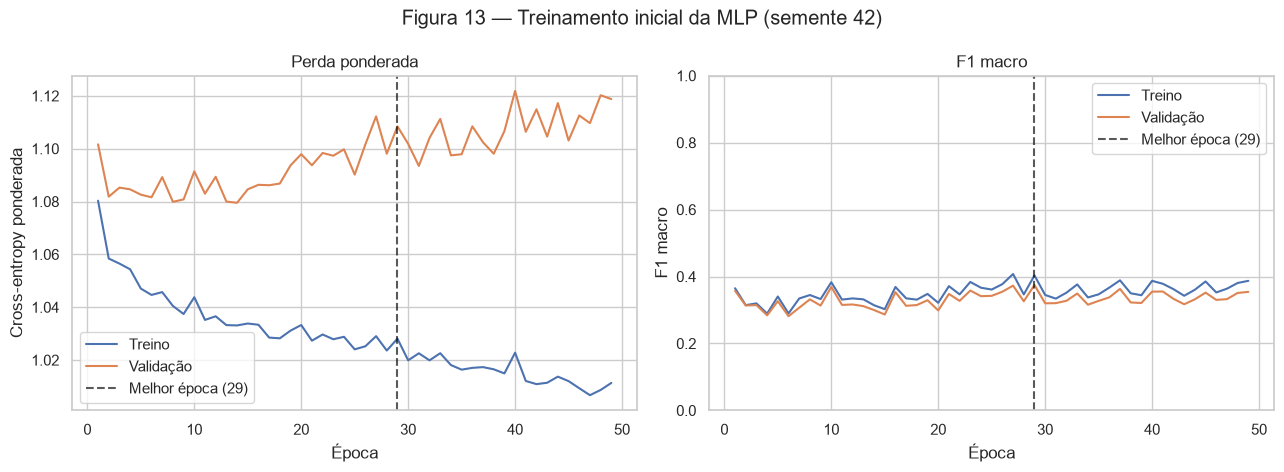

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, train_col, val_col, title, ylabel in [
    (axes[0], "train_loss", "val_loss", "Perda ponderada", "Cross-entropy ponderada"),
    (axes[1], "train_f1_macro", "val_f1_macro", "F1 macro", "F1 macro"),
]:
    ax.plot(history["epoch"], history[train_col], label="Treino")
    ax.plot(history["epoch"], history[val_col], label="Validação")
    ax.axvline(mlp_result.best_epoch, color="black", linestyle="--", alpha=0.65,
               label=f"Melhor época ({mlp_result.best_epoch})")
    ax.set(title=title, xlabel="Época", ylabel=ylabel)
    ax.legend()
axes[1].set_ylim(0, 1)
fig.suptitle("Figura 13 — Treinamento inicial da MLP (semente 42)")
fig.tight_layout()
FIGURE_PATH = FIGURES_DIR / "fig13-mlp-treino-validacao.png"
fig.savefig(FIGURE_PATH, dpi=170, bbox_inches="tight")
plt.show()


### 3.3. Comparação na validação com os melhores pesos

A tabela compara a rede restaurada e os baselines nas mesmas linhas de
validação. As previsões da rede são convertidas dos índices para os nomes das
classes antes de usar as mesmas funções de métricas dos baselines.


In [29]:
mlp_train_metrics = evaluate_mlp(mlp_model, X_train_t, y_train_encoded, class_weights)
mlp_val_metrics = evaluate_mlp(mlp_model, X_val_t, y_val_encoded, class_weights)
assert np.isclose(mlp_val_metrics["f1_macro"], mlp_result.best_val_f1)
class_names = np.asarray(CLASS_LABELS)
mlp_pred_train = class_names[mlp_train_metrics["predictions"]]
mlp_pred_val = class_names[mlp_val_metrics["predictions"]]

mlp_report = classification_report(
    y_val, mlp_pred_val, labels=CLASS_LABELS, output_dict=True, zero_division=0,
)
mlp_row = pd.DataFrame([{
    "f1_macro_treino": f1_macro(y_train, mlp_pred_train),
    "f1_macro_val": f1_macro(y_val, mlp_pred_val),
    "diferenca_treino_val": f1_macro(y_train, mlp_pred_train) - f1_macro(y_val, mlp_pred_val),
    "acuracia_val": accuracy_score(y_val, mlp_pred_val),
    "recall_sofisticada_val": mlp_report["Sofisticada"]["recall"],
    "f1_sofisticada_val": mlp_report["Sofisticada"]["f1-score"],
}], index=["MLP inicial — semente 42"])
comparison_val = pd.concat([baseline_results, mlp_row]).sort_values(
    "f1_macro_val", ascending=False, kind="stable",
)
display(comparison_val.round(4))
display(pd.DataFrame(mlp_report).T.loc[CLASS_LABELS + ["macro avg", "weighted avg"]].round(4))

mlp_f1 = float(mlp_val_metrics["f1_macro"])
relative_gain = (mlp_f1 / best_baseline_f1 - 1) * 100
criterion_met_val = bool(mlp_f1 >= mlp_target_f1)
print(f"F1 macro da MLP na validação: {mlp_f1:.4f}.")
print(f"Variação relativa ao melhor baseline ({best_baseline_name}): {relative_gain:+.2f}%.")
print(f"Critério prévio na validação (meta {mlp_target_f1:.4f}) atingido: {criterion_met_val}.")
print(f"Sofisticada: recall = {mlp_report['Sofisticada']['recall']:.4f}; "
      f"F1 = {mlp_report['Sofisticada']['f1-score']:.4f}.")


,f1_macro_treino,f1_macro_val,diferenca_treino_val,acuracia_val,recall_sofisticada_val,f1_sofisticada_val
MLP inicial — semente 42,0.4033,0.3747,0.0286,0.4975,0.1307,0.0763
Logística,0.3509,0.3550,-0.0042,0.5577,0.0000,0.0000
Logística balanceada,0.3195,0.3102,0.0093,0.4070,0.3268,0.0934
Dummy majoritário,0.2303,0.2303,0.0000,0.5278,0.0000,0.0000


,precision,recall,f1-score,support
Conservadora,0.5091,0.6797,0.5822,1642.0
Moderada,0.6099,0.3764,0.4655,2006.0
Sofisticada,0.0539,0.1307,0.0763,153.0
macro avg,0.3910,0.3956,0.3747,3801.0
weighted avg,0.5440,0.4975,0.5002,3801.0


F1 macro da MLP na validação: 0.3747.
Variação relativa ao melhor baseline (Logística): +5.53%.
Critério prévio na validação (meta 0.3905) atingido: False.
Sofisticada: recall = 0.1307; F1 = 0.0763.


In [30]:
best_history = history.loc[history["epoch"] == mlp_result.best_epoch].iloc[0]
last_history = history.iloc[-1]
train_val_gap = mlp_train_metrics["f1_macro"] - mlp_val_metrics["f1_macro"]
print(f"Na melhor época ({mlp_result.best_epoch}): perda treino = {best_history['train_loss']:.4f}; "
      f"perda validação = {best_history['val_loss']:.4f}.")
print(f"Diferença de F1 macro treino − validação nos pesos restaurados: {train_val_gap:+.4f}.")
if mlp_result.stopped_early:
    print(f"O F1 macro da validação ficou sem um novo máximo por {training_config.patience} "
          f"épocas; o treino parou na época {mlp_result.epochs_run}.")
else:
    print("O treino chegou ao limite de épocas; a parada antecipada não foi acionada.")
if last_history["train_loss"] < best_history["train_loss"] and last_history["val_loss"] > best_history["val_loss"]:
    print("Após o checkpoint escolhido, a perda de treino caiu e a de validação aumentou: "
          "isso indica overfitting nesse trecho.")
else:
    print("O trecho posterior ao checkpoint deve ser lido nas curvas; "
          "as duas perdas, isoladamente, não indicaram esse padrão de overfitting.")

summary = {
    "seed": RANDOM_STATE,
    "architecture": MLP_CONFIG,
    "training": asdict(training_config),
    "class_labels": CLASS_LABELS,
    "class_weights": class_weights.tolist(),
    "feature_names": feature_names.tolist(),
    "n_train": len(X_train), "n_val": len(X_val),
    "n_parameters": actual_parameters,
    "best_epoch": mlp_result.best_epoch,
    "epochs_run": mlp_result.epochs_run,
    "stopped_early": mlp_result.stopped_early,
    "duration_seconds": mlp_result.duration_seconds,
    "val_f1_macro": mlp_f1,
    "best_baseline": best_baseline_name,
    "baseline_f1_macro_val": best_baseline_f1,
    "mlp_target_f1_val": mlp_target_f1,
    "relative_gain_percent": relative_gain,
    "criterion_met_val": criterion_met_val,
    "validation_comparison": comparison_val.to_dict(orient="index"),
    "classification_report_val": mlp_report,
}
(RESULTS_DIR / "mlp_initial_seed42_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8",
)


Na melhor época (29): perda treino = 1.0281; perda validação = 1.1084.
Diferença de F1 macro treino − validação nos pesos restaurados: +0.0286.
O F1 macro da validação ficou sem um novo máximo por 20 épocas; o treino parou na época 49.
Após o checkpoint escolhido, a perda de treino caiu e a de validação aumentou: isso indica overfitting nesse trecho.


3583

### 3.4. Interpretação do primeiro treinamento

A rede obteve **F1 macro de 0,3747 na validação**, contra **0,3550** do melhor
baseline, ganho relativo de **5,53%**. O critério prévio de 10% (**meta de 0,3905**)
**não foi atingido**. A acurácia da rede foi de **49,75%**, enquanto a logística
teve 55,77%; as duas métricas descrevem aspectos diferentes do resultado.

O maior F1 macro de validação ocorreu na **época 29**. Após 20 épocas sem um novo
máximo, o treino parou na **época 49** e restaurou os pesos da época 29. O F1 macro
no treino, nesses pesos, foi **0,4033**, uma diferença de **0,0286** para a validação.

Na Figura 13, a perda de treino caiu de **1,0803** na primeira época para
**1,0113** na última. A perda de validação atingiu seu mínimo de **1,0795 na época
14** e terminou em **1,1187**. A queda da perda de treino acompanhada de aumento
na validação, aproximadamente após a época 15, sugere overfitting. O F1 macro
oscila e não apresenta uma melhora sustentada que justifique continuar o treino.
A época de menor perda difere da escolhida porque a seleção foi definida pelo
F1 macro antes do experimento.

Para `Sofisticada`, a MLP acertou **20 dos 153 exemplos** da validação: recall de
**13,07%**, precisão de **5,39%** e F1 de **0,0763**. O desempenho nessa classe
permanece baixo. A logística balanceada recuperou 32,68% da classe e teve F1 de
0,0934, embora seu F1 macro global fosse menor que o da MLP.

O experimento mostra um ganho inicial no F1 macro, ainda insuficiente para o
critério definido. A próxima comparação investigará regularização e
hiperparâmetros na validação. Uma única semente não permite concluir que o ganho
seja estável, e o conjunto de teste permanece reservado.


O experimento anterior é a referência com uma única semente. A seção seguinte
compara regularização e hiperparâmetros usando a mesma validação. A diferença
para os baselines precisará ser confirmada com múltiplas sementes na etapa final.
O critério de ganho relativo de 10% deverá ser confirmado comparando rede e
baselines no mesmo teste, depois de congelar as decisões tomadas na validação.


## 4. Regularização e hiperparâmetros

### 4.1. Plano definido antes da busca

A perda da validação aumentou enquanto a perda do treino continuou caindo no
experimento inicial. Vamos testar duas formas de limitar o ajuste aos exemplos
de treino: **dropout de 20% nas camadas ocultas** e **weight decay de 0,001 no
Adam**. Também comparamos a combinação das duas com a rede sem regularização.
Os pesos de classe tratam desbalanceamento e não contam como uma dessas técnicas.

A busca é um produto completo de **2 arquiteturas × 2 taxas × 4 opções de
regularização = 16 configurações**, fixado antes de observar seus resultados:

| Fator | Valores | Motivo |
|---|---|---|
| Camadas ocultas | 32/16 e 64/32 | A rede menor reduz a capacidade e permite verificar se a referência tem parâmetros em excesso. |
| Learning rate | 0,001 e 0,0003 | Compara a taxa inicial a atualizações menores, que podem reduzir oscilações. |
| Regularização | Nenhuma; dropout 0,2; weight decay 0,001; ambas | Separa o efeito de cada técnica e de sua combinação, mantendo os outros fatores iguais. |

Mantemos treino, validação, pré-processamento, pesos de classe, batch 64, Adam,
limite de 200 épocas, paciência 20 e semente 42. Cada configuração começa com
uma rede nova e com a semente reiniciada. Dentro da mesma arquitetura, o gerador
separado do DataLoader mantém o embaralhamento igual, inclusive com dropout.

A escolha usa **maior F1 macro na validação**, sem arredondamento. Em empate,
preferimos menos parâmetros e, persistindo o empate, o menor identificador da
configuração. A comparação do efeito de regularização considera sempre a rede
sem regularização com a **mesma arquitetura e taxa**. A busca usa uma semente;
a média entre configurações não é uma estimativa de variação entre sementes.


In [27]:
from itertools import product

regularization_options = [
    ("Nenhuma", 0.0, 0.0),
    ("Dropout", 0.2, 0.0),
    ("Weight decay", 0.0, 1e-3),
    ("Dropout + weight decay", 0.2, 1e-3),
]
search_plan = []
for i, (widths, rate, regularization) in enumerate(
    product([(32, 16), (64, 32)], [1e-3, 3e-4], regularization_options), start=1,
):
    name, dropout, decay = regularization
    search_plan.append({
        "experiment_id": f"C{i:02d}",
        "hidden_dims": widths,
        "arquitetura": "/".join(map(str, widths)),
        "learning_rate": rate,
        "regularizacao": name,
        "dropout": dropout,
        "weight_decay": decay,
    })
assert len(search_plan) == 16
assert len({(c["hidden_dims"], c["learning_rate"], c["dropout"], c["weight_decay"]) for c in search_plan}) == 16
SEARCH_RESULTS_DIR = RESULTS_DIR / "search_seed42"
SEARCH_CHECKPOINT_DIR = PROJECT_ROOT / ".cache" / "classification" / "search_seed42"
SEARCH_RESULTS_DIR.mkdir(exist_ok=True)
SEARCH_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
initial_summary = json.loads((RESULTS_DIR / "mlp_initial_seed42_summary.json").read_text(encoding="utf-8"))
initial_history = pd.read_csv(RESULTS_DIR / "mlp_initial_seed42_history.csv")
assert initial_summary["feature_names"] == feature_names.tolist()
assert np.allclose(initial_summary["class_weights"], class_weights)

plan_record = {
    "selection_metric": "f1_macro_val",
    "tie_break": ["n_parameters", "experiment_id"],
    "shared_training": asdict(training_config),
    "n_train": len(X_train), "n_val": len(X_val),
    "feature_names": feature_names.tolist(),
    "class_labels": CLASS_LABELS,
    "class_weights": class_weights.tolist(),
    "configurations": search_plan,
}
(RESULTS_DIR / "search_plan_seed42.json").write_text(
    json.dumps(plan_record, ensure_ascii=False, indent=2), encoding="utf-8",
)
display(pd.DataFrame(search_plan).set_index("experiment_id"))


,hidden_dims,arquitetura,learning_rate,regularizacao,dropout,weight_decay
experiment_id,,,,,,
C01,"(32, 16)",32/16,0.0010,Nenhuma,0.0,0.000
C02,"(32, 16)",32/16,0.0010,Dropout,0.2,0.000
C03,"(32, 16)",32/16,0.0010,Weight decay,0.0,0.001
C04,"(32, 16)",32/16,0.0010,Dropout + weight decay,0.2,0.001
C05,"(32, 16)",32/16,0.0003,Nenhuma,0.0,0.000
C06,"(32, 16)",32/16,0.0003,Dropout,0.2,0.000
C07,"(32, 16)",32/16,0.0003,Weight decay,0.0,0.001
C08,"(32, 16)",32/16,0.0003,Dropout + weight decay,0.2,0.001
C09,"(64, 32)",64/32,0.0010,Nenhuma,0.0,0.000


### 4.2. Execução dos experimentos

Cada execução restaura os pesos da sua melhor época antes de medir o desempenho.
O histórico e o relatório de cada configuração ficam em `results/search_seed42/`;
os checkpoints ficam em `.cache/classification/search_seed42/`.


In [28]:
grid_rows = []
grid_histories = {}
class_names = np.asarray(CLASS_LABELS)

for experiment in search_plan:
    experiment_id = experiment["experiment_id"]
    print(f"[{experiment_id}/{len(search_plan):02d}] rede {experiment['arquitetura']}; "
          f"lr={experiment['learning_rate']}; {experiment['regularizacao']}", flush=True)
    experiment_training = TrainingConfig(**{
        **asdict(training_config),
        "learning_rate": experiment["learning_rate"],
        "weight_decay": experiment["weight_decay"],
        "log_every": 0,
    })
    experiment_result = fit_mlp(
        X_train_t, y_train_encoded, X_val_t, y_val_encoded,
        hidden_dims=experiment["hidden_dims"], n_classes=len(CLASS_LABELS),
        class_weights=class_weights, dropout=experiment["dropout"],
        config=experiment_training,
        checkpoint_path=SEARCH_CHECKPOINT_DIR / f"{experiment_id}.pt",
    )
    train_metrics = evaluate_mlp(experiment_result.model, X_train_t, y_train_encoded, class_weights)
    val_metrics = evaluate_mlp(experiment_result.model, X_val_t, y_val_encoded, class_weights)
    report_val = classification_report(
        y_val, class_names[val_metrics["predictions"]], labels=CLASS_LABELS,
        output_dict=True, zero_division=0,
    )
    row = {
        **experiment,
        "seed": RANDOM_STATE,
        "n_parameters": sum(p.numel() for p in experiment_result.model.parameters()),
        "best_epoch": experiment_result.best_epoch,
        "epochs_run": experiment_result.epochs_run,
        "stopped_early": experiment_result.stopped_early,
        "duration_seconds": experiment_result.duration_seconds,
        "f1_macro_treino": float(train_metrics["f1_macro"]),
        "f1_macro_val": float(val_metrics["f1_macro"]),
        "diferenca_treino_val": float(train_metrics["f1_macro"] - val_metrics["f1_macro"]),
        "val_loss": float(val_metrics["loss"]),
        "acuracia_val": float(report_val["accuracy"]),
        "recall_sofisticada_val": float(report_val["Sofisticada"]["recall"]),
        "f1_sofisticada_val": float(report_val["Sofisticada"]["f1-score"]),
    }
    assert np.isclose(row["f1_macro_val"], experiment_result.best_val_f1)
    experiment_history = pd.DataFrame(experiment_result.history)
    grid_histories[experiment_id] = experiment_history
    experiment_history.to_csv(SEARCH_RESULTS_DIR / f"{experiment_id}_history.csv", index=False)
    (SEARCH_RESULTS_DIR / f"{experiment_id}_summary.json").write_text(
        json.dumps({"result": row, "training": asdict(experiment_training),
                    "classification_report_val": report_val}, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    grid_rows.append(row)
    print(f"  F1 macro val={row['f1_macro_val']:.4f}; melhor época={row['best_epoch']}; "
          f"parou em {row['epochs_run']}; duração={row['duration_seconds']:.1f}s", flush=True)

grid_results = (
    pd.DataFrame(grid_rows)
    .sort_values(["f1_macro_val", "n_parameters", "experiment_id"], ascending=[False, True, True])
    .set_index("experiment_id")
)
grid_results.to_csv(RESULTS_DIR / "search_results_seed42.csv")
reference_id = next(c["experiment_id"] for c in search_plan if
    c["hidden_dims"] == (64, 32) and c["learning_rate"] == 1e-3 and c["regularizacao"] == "Nenhuma")
assert np.isclose(grid_results.loc[reference_id, "f1_macro_val"], initial_summary["val_f1_macro"])
print("A rede de referência reproduziu o F1 macro do primeiro experimento.")


[C01/16] rede 32/16; lr=0.001; Nenhuma


  F1 macro val=0.3829; melhor época=29; parou em 49; duração=23.3s


[C02/16] rede 32/16; lr=0.001; Dropout


  F1 macro val=0.3399; melhor época=3; parou em 23; duração=11.0s


[C03/16] rede 32/16; lr=0.001; Weight decay


  F1 macro val=0.3714; melhor época=27; parou em 47; duração=19.6s


... (23 outputs left out)

  F1 macro val=0.3593; melhor época=33; parou em 53; duração=24.9s


[C16/16] rede 64/32; lr=0.0003; Dropout + weight decay


  F1 macro val=0.3264; melhor época=5; parou em 25; duração=12.9s


A rede de referência reproduziu o F1 macro do primeiro experimento.

### 4.3. Tabela ordenada e comparação controlada

A primeira tabela ordena as 16 configurações pelo critério de seleção. A segunda
mostra a diferença de F1 macro em relação à rede sem regularização de mesma
arquitetura e taxa. Um valor positivo nessa diferença favorece a técnica naquele
par de fatores; não indica, por si só, significância estatística.


In [29]:
search_columns = [
    "arquitetura", "learning_rate", "regularizacao", "n_parameters",
    "best_epoch", "epochs_run", "f1_macro_treino", "f1_macro_val",
    "diferenca_treino_val", "recall_sofisticada_val", "f1_sofisticada_val",
]
display(grid_results[search_columns].round(4))

unregularized = grid_results[grid_results["regularizacao"] == "Nenhuma"].reset_index()[
    ["arquitetura", "learning_rate", "f1_macro_val"]
].rename(columns={"f1_macro_val": "f1_macro_sem_regularizacao"})
controlled_results = grid_results.reset_index().merge(
    unregularized, on=["arquitetura", "learning_rate"], how="left", validate="many_to_one",
)
controlled_results["delta_f1_macro"] = (
    controlled_results["f1_macro_val"] - controlled_results["f1_macro_sem_regularizacao"]
)
controlled_results = controlled_results.sort_values(["arquitetura", "learning_rate", "regularizacao"])
controlled_results.to_csv(RESULTS_DIR / "regularization_comparison_seed42.csv", index=False)
display(controlled_results[[
    "experiment_id", "arquitetura", "learning_rate", "regularizacao",
    "f1_macro_val", "delta_f1_macro", "diferenca_treino_val",
]].round(4))
regularization_effects = controlled_results.groupby("regularizacao")["delta_f1_macro"].agg(
    media="mean", minimo="min", maximo="max",
).reindex([r[0] for r in regularization_options])
print("Diferenças relativas aos controles, resumidas entre quatro pares de arquitetura/taxa:")
display(regularization_effects.round(4))


,arquitetura,learning_rate,regularizacao,n_parameters,best_epoch,epochs_run,f1_macro_treino,f1_macro_val,diferenca_treino_val,recall_sofisticada_val,f1_sofisticada_val
experiment_id,,,,,,,,,,,
C01,32/16,0.0010,Nenhuma,1123,29,49,0.3929,0.3829,0.0100,0.2026,0.1082
C09,64/32,0.0010,Nenhuma,3267,29,49,0.4033,0.3747,0.0286,0.1307,0.0763
C03,32/16,0.0010,Weight decay,1123,27,47,0.3740,0.3714,0.0025,0.2418,0.1071
C07,32/16,0.0003,Weight decay,1123,1,21,0.3630,0.3681,-0.0051,0.1111,0.0717
C05,32/16,0.0003,Nenhuma,1123,1,21,0.3623,0.3677,-0.0054,0.1111,0.0714
C15,64/32,0.0003,Weight decay,3267,33,53,0.3793,0.3593,0.0200,0.1961,0.0916
C13,64/32,0.0003,Nenhuma,3267,29,49,0.3768,0.3579,0.0189,0.1961,0.0910
C12,64/32,0.0010,Dropout + weight decay,3267,5,25,0.3525,0.3537,-0.0013,0.2092,0.0985
C11,64/32,0.0010,Weight decay,3267,1,21,0.3624,0.3528,0.0096,0.1242,0.0706


,experiment_id,arquitetura,learning_rate,regularizacao,f1_macro_val,delta_f1_macro,diferenca_treino_val
10,C06,32/16,0.0003,Dropout,0.3514,-0.0163,0.0083
9,C08,32/16,0.0003,Dropout + weight decay,0.3524,-0.0153,0.0089
4,C05,32/16,0.0003,Nenhuma,0.3677,0.0000,-0.0054
3,C07,32/16,0.0003,Weight decay,0.3681,0.0004,-0.0051
12,C02,32/16,0.0010,Dropout,0.3399,-0.0429,0.0091
13,C04,32/16,0.0010,Dropout + weight decay,0.3344,-0.0485,0.0085
0,C01,32/16,0.0010,Nenhuma,0.3829,0.0000,0.0100
2,C03,32/16,0.0010,Weight decay,0.3714,-0.0115,0.0025
15,C14,64/32,0.0003,Dropout,0.3259,-0.0320,0.0075
14,C16,64/32,0.0003,Dropout + weight decay,0.3264,-0.0315,0.0076


Diferenças relativas aos controles, resumidas entre quatro pares de arquitetura/taxa:


,media,minimo,maximo
regularizacao,,,
Nenhuma,0.0000,0.0000,0.0000
Dropout,-0.0296,-0.0429,-0.0163
Weight decay,-0.0079,-0.0219,0.0014
Dropout + weight decay,-0.0291,-0.0485,-0.0153


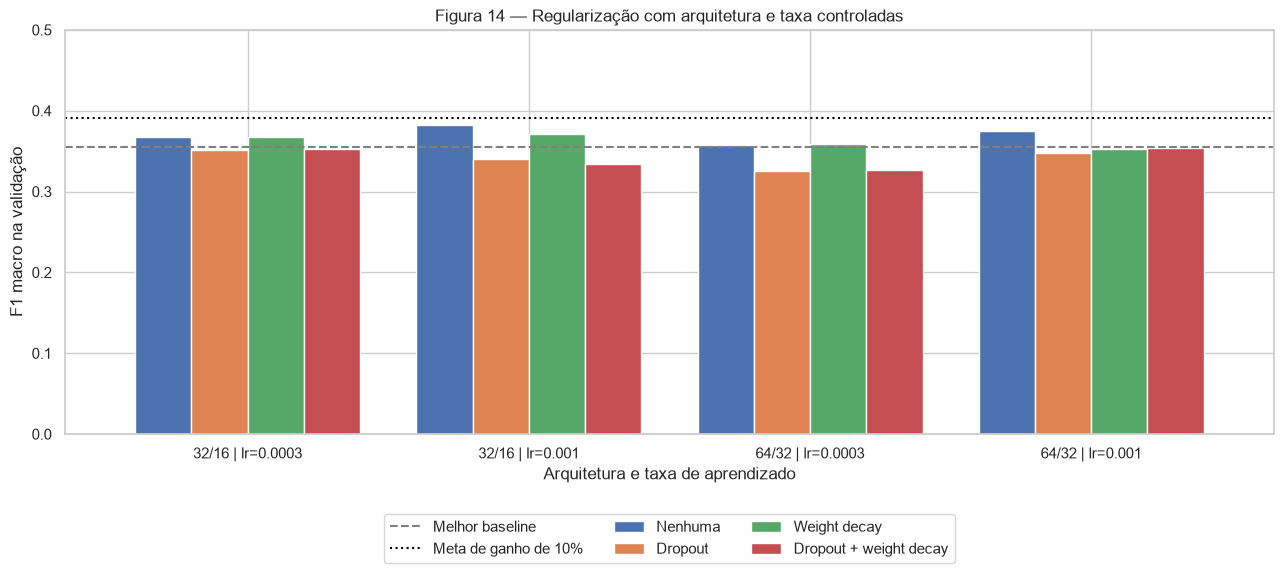

In [30]:
plot_data = controlled_results.copy()
plot_data["grupo"] = plot_data["arquitetura"] + " | lr=" + plot_data["learning_rate"].map(lambda x: f"{x:g}")
comparison_plot = plot_data.pivot(index="grupo", columns="regularizacao", values="f1_macro_val")
comparison_plot = comparison_plot.reindex(columns=[r[0] for r in regularization_options])
ax = comparison_plot.plot.bar(figsize=(13, 6), width=0.8, rot=0)
ax.axhline(best_baseline_f1, color="grey", linestyle="--", label="Melhor baseline")
ax.axhline(mlp_target_f1, color="black", linestyle=":", label="Meta de ganho de 10%")
ax.set(title="Figura 14 — Regularização com arquitetura e taxa controladas",
       xlabel="Arquitetura e taxa de aprendizado", ylabel="F1 macro na validação")
ax.set_ylim(0, max(0.5, grid_results["f1_macro_val"].max() + 0.06))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig14-regularizacao-validacao.png", dpi=170, bbox_inches="tight")
plt.show()


### 4.4. Configuração selecionada pela validação

A seleção considera o maior F1 macro, com os desempates definidos no plano.
Carregamos o checkpoint correspondente e conferimos a métrica, em vez de usar
os pesos da última época. Esta é a candidata para a etapa final, sem avaliação
de desempenho no teste nesta seção.


In [31]:
best_experiment_id = grid_results.index[0]
selected_config = next(c for c in search_plan if c["experiment_id"] == best_experiment_id)
selected_row = grid_results.loc[best_experiment_id]
selected_model = MLP(
    input_dim=X_train_t.shape[1], hidden_dims=selected_config["hidden_dims"],
    output_dim=len(CLASS_LABELS), dropout=selected_config["dropout"],
)
selected_model.load_state_dict(torch.load(
    SEARCH_CHECKPOINT_DIR / f"{best_experiment_id}.pt", map_location="cpu", weights_only=True,
))
selected_model.eval()
selected_val_metrics = evaluate_mlp(selected_model, X_val_t, y_val_encoded, class_weights)
assert np.isclose(selected_val_metrics["f1_macro"], selected_row["f1_macro_val"])
selected_history = grid_histories[best_experiment_id]
selected_report = classification_report(
    y_val, class_names[selected_val_metrics["predictions"]], labels=CLASS_LABELS,
    output_dict=True, zero_division=0,
)
torch.save(selected_model.state_dict(), PROJECT_ROOT / ".cache" / "classification" / "mlp_selected_seed42.pt")
selected_f1 = float(selected_row["f1_macro_val"])
selected_gain = (selected_f1 / best_baseline_f1 - 1) * 100
selected_criterion_met = bool(selected_f1 >= mlp_target_f1)
print(f"Selecionada: {best_experiment_id}; rede {selected_config['arquitetura']}; "
      f"lr={selected_config['learning_rate']}; {selected_config['regularizacao']}.")
print(f"F1 macro validação: {selected_f1:.4f}; variação ao baseline: {selected_gain:+.2f}%.")
print(f"Meta {mlp_target_f1:.4f} atingida na validação: {selected_criterion_met}.")
print(f"Melhor época: {int(selected_row['best_epoch'])}; épocas executadas: {int(selected_row['epochs_run'])}.")
display(pd.DataFrame(selected_report).T.loc[CLASS_LABELS + ["macro avg", "weighted avg"]].round(4))

initial_row = pd.DataFrame(
    {"MLP inicial — semente 42": initial_summary["validation_comparison"]["MLP inicial — semente 42"]}
).T
selected_comparison_row = pd.DataFrame([selected_row[baseline_results.columns].to_dict()],
                                     index=[f"MLP selecionada ({best_experiment_id})"])
comparison_after_search = pd.concat([baseline_results, initial_row, selected_comparison_row]).sort_values(
    "f1_macro_val", ascending=False, kind="stable",
)
display(comparison_after_search.round(4))

selected_summary = {
    "experiment_id": best_experiment_id, "configuration": selected_config,
    "training": {**asdict(training_config), "learning_rate": selected_config["learning_rate"],
                 "weight_decay": selected_config["weight_decay"], "log_every": 0},
    "n_configurations": len(search_plan), "selection_metric": "f1_macro_val",
    "seed": RANDOM_STATE, "n_train": len(X_train), "n_val": len(X_val),
    "feature_names": feature_names.tolist(), "class_labels": CLASS_LABELS,
    "class_weights": class_weights.tolist(), "n_parameters": int(selected_row["n_parameters"]),
    "best_epoch": int(selected_row["best_epoch"]), "epochs_run": int(selected_row["epochs_run"]),
    "val_f1_macro": selected_f1, "baseline_f1_macro_val": best_baseline_f1,
    "mlp_target_f1_val": mlp_target_f1, "relative_gain_percent": selected_gain,
    "criterion_met_val": selected_criterion_met, "classification_report_val": selected_report,
    "regularization_effects": regularization_effects.to_dict(orient="index"),
    "validation_comparison": comparison_after_search.to_dict(orient="index"),
}
(RESULTS_DIR / "mlp_selected_seed42_summary.json").write_text(
    json.dumps(selected_summary, ensure_ascii=False, indent=2), encoding="utf-8",
)


Selecionada: C01; rede 32/16; lr=0.001; Nenhuma.
F1 macro validação: 0.3829; variação ao baseline: +7.85%.
Meta 0.3905 atingida na validação: False.
Melhor época: 29; épocas executadas: 49.


,precision,recall,f1-score,support
Conservadora,0.5125,0.7138,0.5966,1642.0
Moderada,0.6289,0.3430,0.4439,2006.0
Sofisticada,0.0738,0.2026,0.1082,153.0
macro avg,0.4051,0.4198,0.3829,3801.0
weighted avg,0.5562,0.4975,0.4963,3801.0


,f1_macro_treino,f1_macro_val,diferenca_treino_val,acuracia_val,recall_sofisticada_val,f1_sofisticada_val
MLP selecionada (C01),0.3929,0.3829,0.0100,0.4975,0.2026,0.1082
MLP inicial — semente 42,0.4033,0.3747,0.0286,0.4975,0.1307,0.0763
Logística,0.3509,0.3550,-0.0042,0.5577,0.0000,0.0000
Logística balanceada,0.3195,0.3102,0.0093,0.4070,0.3268,0.0934
Dummy majoritário,0.2303,0.2303,0.0000,0.5278,0.0000,0.0000


4498

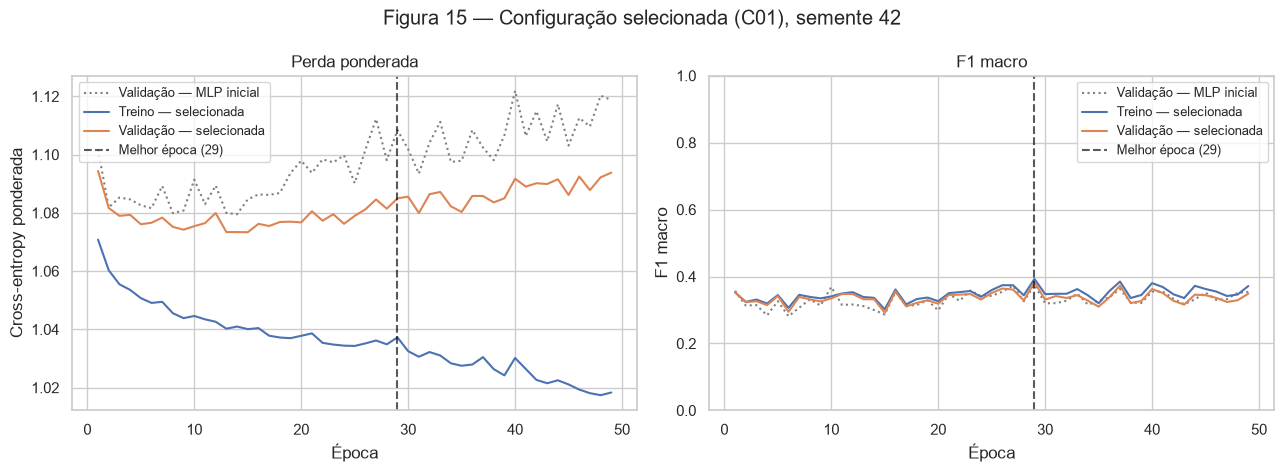

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, train_col, val_col, title, ylabel in [
    (axes[0], "train_loss", "val_loss", "Perda ponderada", "Cross-entropy ponderada"),
    (axes[1], "train_f1_macro", "val_f1_macro", "F1 macro", "F1 macro"),
]:
    ax.plot(initial_history["epoch"], initial_history[val_col], color="grey", linestyle=":",
            label="Validação — MLP inicial")
    ax.plot(selected_history["epoch"], selected_history[train_col], label="Treino — selecionada")
    ax.plot(selected_history["epoch"], selected_history[val_col], label="Validação — selecionada")
    ax.axvline(int(selected_row["best_epoch"]), color="black", linestyle="--", alpha=0.65,
               label=f"Melhor época ({int(selected_row['best_epoch'])})")
    ax.set(title=title, xlabel="Época", ylabel=ylabel)
    ax.legend(fontsize=9)
axes[1].set_ylim(0, 1)
fig.suptitle(f"Figura 15 — Configuração selecionada ({best_experiment_id}), semente 42")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig15-melhor-configuracao-validacao.png", dpi=170, bbox_inches="tight")
plt.show()


### 4.5. Interpretação da comparação

As **16 configurações** foram executadas com a semente 42, totalizando cerca de
**281,7 segundos de ajuste**, sem contar a preparação dos dados. A rede de
referência 64/32 sem regularização reproduziu seu F1 macro de **0,3747**.

A seleção pelo maior F1 macro escolheu **C01: 16 → 32 → 16 → 3**, learning rate
**0,001**, dropout **0** e weight decay **0**. São **1.123 parâmetros**, contra
3.267 da referência inicial, para as mesmas 11.402 linhas de treino. O F1 macro
na validação subiu para **0,3829**; no treino foi **0,3929**, diferença de **0,0100**.
A menor capacidade melhorou o resultado nesta divisão e reduziu a diferença de
F1 entre treino e validação em relação aos 0,0286 da rede inicial.

Na comparação com controles de mesma arquitetura e taxa, **dropout de 0,2
reduziu o F1 macro nos quatro pares**, com diferença média de **−0,0296**.
**Weight decay de 0,001** trouxe melhoras pequenas nos dois pares com taxa
0,0003 (**+0,0004** para 32/16 e **+0,0014** para 64/32), e piorou os dois pares
com taxa 0,001. Sua diferença média foi **−0,0079**. A combinação das técnicas
piorou os quatro controles, com média **−0,0291**. Essas médias são entre
configurações, sem representar desvio entre sementes.

A Figura 14 torna visível que nenhuma configuração ultrapassou a meta de
**0,3905**. O ganho da selecionada em relação à logística foi de **7,85%**;
**o critério de sucesso de 10% não foi atingido na validação**. Os resultados
não sustentam escolher dropout ou weight decay nas intensidades e no orçamento
testados. Isso não demonstra que essas técnicas sejam inadequadas em geral.

Na Figura 15, a perda de validação da rede menor é inferior à da referência
inicial ao longo de grande parte do treino. Ainda há divergência: ela atinge
mínimo de **1,0733 na época 15** e sobe para **1,0938 na época 49**, enquanto a
perda de treino cai de **1,0708** para **1,0183**. O F1 macro oscila. A seleção
permanece na **época 29**, e a parada ocorre na **49**, restaurando os melhores
pesos. A rede menor atenuou a diferença observada, sem eliminar o sinal de
overfitting na perda.

Em `Sofisticada`, a selecionada acertou **31 dos 153 exemplos**: recall de
**20,26%**, precisão de **7,38%** e F1 de **0,1082**. A rede inicial acertava 20,
com F1 de 0,0763. O desempenho nessa classe segue baixo e deve ser acompanhado
na avaliação final. A candidata escolhida usa uma única semente; ainda faltam
a confirmação da variabilidade e a avaliação final no teste.


A busca e a seleção desta seção usam a mesma divisão de validação e uma única
semente. O máximo entre 16 configurações pode ser otimista para essa divisão.
A próxima etapa deverá congelar a configuração e realizar a avaliação final,
incluindo a variação entre pelo menos três sementes. Os pesos de classe e a
regra de decisão `argmax` permaneceram iguais durante toda a comparação.


## 5. Regra de decisão e avaliação final no teste

### 5.1. Regra escolhida somente na validação

Não foi fornecida uma matriz de custos de negócio ou valores monetários para
os erros. A regra usa o objetivo acadêmico já definido: **F1 macro**, dando o
mesmo peso às três classes. A precisão baixa de `Sofisticada` torna relevante
acompanhar falsos positivos, inclusive Conservadora prevista como Sofisticada;
não presumimos que esse custo tenha sido quantificado.

Comparamos o `argmax` a limiares relativos: prever a classe que maximiza
`p_k * fator_k`, equivalente a `p_k / t_k`, com `t_k = 1 / fator_k`. Fixamos o
fator de Conservadora em 1 e variamos os outros em **0,5; 0,75; 1; 1,25; 1,5**:
**25 regras por modelo**, incluindo o argmax (todos os fatores iguais a 1).
A mesma comparação é aplicada à MLP selecionada e aos três baselines.

Escolhemos maior F1 macro na validação; em empate, fatores mais próximos de 1,
depois ordem numérica. Os fatores só alteram as classes previstas. ROC e PR
usam as probabilidades originais. As saídas softmax da perda ponderada não
foram calibradas e não são interpretadas como probabilidades de perdas financeiras.

A arquitetura C01 permanece fixa. O ajuste da regra pode mudar o melhor
baseline da validação e, portanto, o valor numérico da meta; a regra de sucesso
permanece **ganho relativo de pelo menos 10% sobre o baseline escolhido na
validação**. O teste não participa dessas decisões.


#### Regras de decisão e métricas definidas no notebook


In [ ]:
"""Regras multiclasse e métricas; seleção recebe apenas dados de validação."""

from itertools import product

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, auc, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_recall_curve, roc_auc_score,
)


def validate_probabilities(probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    if probabilities.ndim != 2 or probabilities.shape[1] != 3:
        raise ValueError("São esperadas três colunas de probabilidades.")
    if not np.isfinite(probabilities).all() or (probabilities < 0).any():
        raise ValueError("Probabilidades devem ser finitas e não negativas.")
    if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5):
        raise ValueError("As probabilidades devem somar um por exemplo.")
    return probabilities


def align_probabilities(probabilities, estimator_classes, class_labels):
    """Alinha as colunas de um baseline à ordem fixa dos logits da rede."""
    order = [list(estimator_classes).index(label) for label in class_labels]
    return validate_probabilities(np.asarray(probabilities)[:, order])


def apply_decision_rule(probabilities, factors=(1.0, 1.0, 1.0)):
    """Argmax de p_k * fator_k; equivale a limiares relativos t_k=1/fator_k.

    Os fatores só afetam a classe prevista. ROC/PR usam as probabilidades
    originais, sem renormalizar as pontuações ajustadas.
    """
    probabilities = validate_probabilities(probabilities)
    factors = np.asarray(factors, dtype=float)
    if factors.shape != (3,) or not np.isfinite(factors).all() or (factors <= 0).any():
        raise ValueError("Informe três fatores finitos e positivos.")
    return (probabilities * factors).argmax(axis=1)


def select_decision_rule(y_val, probabilities, *, protect_conservative=False):
    """Compara 25 regras na validação; o controle é o argmax convencional.

    O fator de Conservadora fica em 1. Os outros variam em uma grade fixa.
    Empates em F1 favorecem fatores mais próximos de (1,1,1), depois ordem
    numérica dos fatores. A opção de proteção não presume valores monetários:
    impede aumentar Conservadora->Sofisticada em relação ao argmax.
    """
    probabilities = validate_probabilities(probabilities)
    y_val = np.asarray(y_val, dtype=int)
    if y_val.shape != (len(probabilities),) or not np.isin(y_val, [0, 1, 2]).all():
        raise ValueError("Os alvos de validação devem usar índices 0, 1 e 2.")
    control = apply_decision_rule(probabilities)
    control_errors = int(((y_val == 0) & (control == 2)).sum())
    rows = []
    for moderate, sophisticated in product([0.5, 0.75, 1.0, 1.25, 1.5], repeat=2):
        factors = (1.0, moderate, sophisticated)
        predictions = apply_decision_rule(probabilities, factors)
        errors = int(((y_val == 0) & (predictions == 2)).sum())
        rows.append({
            "factor_conservadora": 1.0, "factor_moderada": moderate,
            "factor_sofisticada": sophisticated,
            "f1_macro_val": f1_score(y_val, predictions, labels=[0, 1, 2],
                                      average="macro", zero_division=0),
            "accuracy_val": accuracy_score(y_val, predictions),
            "conservadora_as_sofisticada": errors,
            "eligible": not protect_conservative or errors <= control_errors,
            "distance_from_argmax": float(np.abs(np.log(factors)).sum()),
        })
    table = pd.DataFrame(rows).sort_values(
        ["eligible", "f1_macro_val", "distance_from_argmax", "factor_moderada", "factor_sofisticada"],
        ascending=[False, False, True, True, True], kind="stable",
    ).reset_index(drop=True)
    best = table.iloc[0]
    factors = [float(best[f"factor_{name}"]) for name in ["conservadora", "moderada", "sofisticada"]]
    return factors, table


def classification_metrics(y_true, probabilities, factors, class_labels):
    """Métricas multiclasse e áreas OvR, com convenções explícitas de PR-AUC."""
    probabilities = validate_probabilities(probabilities)
    y_true = np.asarray(y_true, dtype=int)
    predictions = apply_decision_rule(probabilities, factors)
    binary = np.eye(3, dtype=int)[y_true]
    per_class = {}
    pr_areas = []
    for index, label in enumerate(class_labels):
        precision, recall, _ = precision_recall_curve(binary[:, index], probabilities[:, index])
        pr_area = auc(recall, precision)
        pr_areas.append(pr_area)
        per_class[label] = {
            "roc_auc_ovr": float(roc_auc_score(binary[:, index], probabilities[:, index])),
            "pr_auc_trapezoidal": float(pr_area),
            "average_precision": float(average_precision_score(binary[:, index], probabilities[:, index])),
        }
    report = classification_report(
        y_true, predictions, labels=[0, 1, 2], target_names=class_labels,
        output_dict=True, zero_division=0,
    )
    overall = {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "f1_macro": float(f1_score(y_true, predictions, labels=[0, 1, 2], average="macro", zero_division=0)),
        "roc_auc_macro_ovr": float(roc_auc_score(y_true, probabilities, labels=[0, 1, 2], multi_class="ovr", average="macro")),
        "pr_auc_macro_trapezoidal": float(np.mean(pr_areas)),
        "average_precision_macro": float(average_precision_score(binary, probabilities, average="macro")),
    }
    return {"overall": overall, "classification_report": report,
            "per_class_areas": per_class,
            "confusion_matrix": confusion_matrix(y_true, predictions, labels=[0, 1, 2]).tolist()}


#### Retreino por número fixo de épocas, sem validação ou teste no laço


In [ ]:
@dataclass(frozen=True)
class FinalTrainingConfig:
    epochs: int = 29
    learning_rate: float = 1e-3
    batch_size: int = 64
    weight_decay: float = 0.0
    seed: int = 42
    num_threads: int = 1


def fit_mlp_fixed_epochs(
    X_train, y_train, *, hidden_dims=(32, 16), n_classes=3,
    class_weights=None, dropout=0.0, config=None, checkpoint_path=None,
):
    """Retreina no treino externo completo, por um número de épocas já fixado.

    Sem argumentos de validação ou teste: nenhuma métrica externa escolhe
    pesos ou duração nesta fase. O modelo devolvido é o da última época fixa.
    """
    config = config or FinalTrainingConfig()
    if min(config.epochs, config.batch_size, config.num_threads) < 1:
        raise ValueError("Épocas, batch e threads devem ser positivos.")
    if config.learning_rate <= 0 or config.weight_decay < 0:
        raise ValueError("Taxa deve ser positiva e weight decay não negativo.")
    input_dim = np.asarray(X_train).shape[1]
    features, targets = _tensors(X_train, y_train, input_dim, n_classes)
    weights = _weights(class_weights, n_classes)
    torch.set_num_threads(config.num_threads)
    seed_everything(config.seed)
    model = MLP(input_dim, hidden_dims, n_classes, dropout)
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay,
    )
    loader = DataLoader(
        TensorDataset(features, targets), batch_size=config.batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(config.seed), num_workers=0,
    )
    history = []
    started = perf_counter()
    for epoch in range(1, config.epochs + 1):
        model.train()
        for inputs, labels in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(inputs), labels)
            if not torch.isfinite(loss):
                raise FloatingPointError("Perda não finita no retreino final.")
            loss.backward()
            optimizer.step()
        metrics = _evaluate(model, features, targets, loss_fn)
        history.append({"epoch": epoch, "train_loss": metrics["loss"],
                        "train_f1_macro": metrics["f1_macro"]})
    model.eval()
    if checkpoint_path is not None:
        checkpoint_path = Path(checkpoint_path)
        checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
        torch.save(model.state_dict(), checkpoint_path)
    return {"model": model, "history": history,
            "duration_seconds": perf_counter() - started}


In [27]:
from datetime import datetime, timezone
import hashlib
import platform
import joblib
import sklearn

FINAL_RESULTS_DIR = RESULTS_DIR / "final"
FINAL_MODEL_DIR = PROJECT_ROOT / ".cache" / "classification" / "final"
FINAL_RESULTS_DIR.mkdir(exist_ok=True)
FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)
PROTECT_CONSERVATIVE = False  # Sem custo adicional de negócio definido.
FINAL_SEEDS = [42, 43, 44]
REPRESENTATIVE_SEED = 42  # Escolhido antes de observar qualquer resultado no teste.
selection_record = json.loads((RESULTS_DIR / "mlp_selected_seed42_summary.json").read_text(encoding="utf-8"))
chosen_configuration = selection_record["configuration"]
FINAL_EPOCHS = selection_record["best_epoch"]  # 29, escolhido na validação.

decision_model = MLP(X_train_t.shape[1], chosen_configuration["hidden_dims"], len(CLASS_LABELS), chosen_configuration["dropout"])
decision_model.load_state_dict(torch.load(
    PROJECT_ROOT / ".cache" / "classification" / "mlp_selected_seed42.pt",
    map_location="cpu", weights_only=True,
))
decision_model.eval()
validation_probabilities = {
    "MLP": evaluate_mlp(decision_model, X_val_t, y_val_encoded, class_weights)["probabilities"],
}
baseline_ids = {"Dummy majoritário": "dummy", "Logística": "logistic", "Logística balanceada": "logistic_balanced"}
for name, model in baseline_models.items():
    validation_probabilities[name] = align_probabilities(model.predict_proba(X_val), model.classes_, CLASS_LABELS)

decision_rules = {}
decision_rows = []
for name, probabilities in validation_probabilities.items():
    factors, candidates = select_decision_rule(y_val_encoded, probabilities, protect_conservative=PROTECT_CONSERVATIVE)
    model_id = "mlp" if name == "MLP" else baseline_ids[name]
    candidates.to_csv(FINAL_RESULTS_DIR / f"validation_rules_{model_id}.csv", index=False)
    selected = candidates.iloc[0]
    control = candidates.loc[(candidates["factor_moderada"] == 1) & (candidates["factor_sofisticada"] == 1)].iloc[0]
    decision_rules[name] = factors
    decision_rows.append({
        "model": name, "model_id": model_id, "factors": factors,
        "f1_macro_argmax": float(control["f1_macro_val"]),
        "f1_macro_val": float(selected["f1_macro_val"]),
        "conservadora_as_sofisticada": int(selected["conservadora_as_sofisticada"]),
    })
decision_results = pd.DataFrame(decision_rows).sort_values(["f1_macro_val", "model_id"], ascending=[False, True])
decision_results.to_csv(FINAL_RESULTS_DIR / "validation_decision_summary.csv", index=False)
final_baseline_name = decision_results.loc[decision_results["model"] != "MLP"].iloc[0]["model"]
final_baseline_val_f1 = float(decision_results.loc[decision_results["model"] == final_baseline_name, "f1_macro_val"].iloc[0])
display(decision_results)
print(f"Baseline escolhido antes do teste: {final_baseline_name}; F1 macro validação={final_baseline_val_f1:.4f}.")
print(f"Meta correspondente na validação: {1.10 * final_baseline_val_f1:.4f}.")

print(decision_results[["model", "factors", "f1_macro_argmax", "f1_macro_val"]].to_string(index=False))


,model,model_id,factors,f1_macro_argmax,f1_macro_val,conservadora_as_sofisticada
0,MLP,mlp,"[1.0, 1.0, 0.75]",0.382888,0.404160,58
3,Logística balanceada,logistic_balanced,"[1.0, 1.0, 0.5]",0.310181,0.382197,5
2,Logística,logistic,"[1.0, 0.75, 1.0]",0.355013,0.375646,0
1,Dummy majoritário,dummy,"[1.0, 1.0, 1.0]",0.230297,0.230297,0


Baseline escolhido antes do teste: Logística balanceada; F1 macro validação=0.3822.
Meta correspondente na validação: 0.4204.
               model          factors  f1_macro_argmax  f1_macro_val
                 MLP [1.0, 1.0, 0.75]         0.382888      0.404160
Logística balanceada  [1.0, 1.0, 0.5]         0.310181      0.382197
           Logística [1.0, 0.75, 1.0]         0.355013      0.375646
   Dummy majoritário  [1.0, 1.0, 1.0]         0.230297      0.230297


### 5.2. Protocolo congelado antes do teste

Retreinaremos a rede **32/16**, taxa 0,001, batch 64, sem dropout e sem weight
decay, nas sementes **42, 43 e 44**, por **29 épocas fixas**. O pré-processador
será ajustado em todo o treino externo (treino + validação, 15.203 linhas), e os
pesos de classe serão recalculados somente nesse conjunto. Não há parada pelo
teste nem seleção de uma nova época durante esse retreino.

Os baselines serão reajustados nas mesmas 15.203 linhas, mantendo seus
hiperparâmetros. Cada modelo conservará a regra escolhida na validação.
A comparação principal usa a **média do F1 macro das três redes** contra o F1
macro do baseline escolhido na validação. Reportamos desvio amostral (`ddof=1`)
entre as três sementes. Baselines determinísticos têm um único ajuste; não
inventamos um desvio para eles. A semente 42 representará as figuras, sem
escolher a melhor semente pelo resultado no teste.

O protocolo, as regras e as impressões digitais dos dados são salvos antes do
retreino. As probabilidades finais são guardadas para calcular tabelas e figuras
sem voltar a consultar os modelos no teste. Uma mudança de protocolo depois
de existirem previsões finais interrompe a execução, evitando retuning nesse teste.


In [28]:
def file_digest(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

final_class_counts = y_train_eda.value_counts().reindex(CLASS_LABELS)
final_class_weights = (len(y_train_eda) / (len(CLASS_LABELS) * final_class_counts.to_numpy())).astype(np.float32)
protocol = {
    "selected_configuration": chosen_configuration,
    "final_epochs": int(FINAL_EPOCHS), "seeds": FINAL_SEEDS,
    "representative_seed": REPRESENTATIVE_SEED,
    "learning_rate": chosen_configuration["learning_rate"], "batch_size": 64,
    "decision_rules": decision_rules,
    "decision_objective": "F1 macro, sem matriz de custos de negócio",
    "protect_conservative": PROTECT_CONSERVATIVE,
    "baseline_selected_on_validation": final_baseline_name,
    "criterion": "mean F1 macro of three MLP seeds >= 1.10 * validation-selected baseline F1 macro on the same test",
    "success_factor": 1.10, "n_train_final": len(X_train_eda),
    "n_holdout": len(X_test), "class_labels": CLASS_LABELS,
    "feature_names": feature_names.tolist(), "class_weights_final": final_class_weights.tolist(),
    "source_files_sha256": {path.name: file_digest(path) for path in [ACCOUNT_PATH, POLICY_PATH, WALLET_PATH]},
    "outer_train_indices_sha256": hashlib.sha256(X_train_eda.index.to_numpy(dtype=np.int64).tobytes()).hexdigest(),
    "holdout_indices_sha256": hashlib.sha256(X_test.index.to_numpy(dtype=np.int64).tobytes()).hexdigest(),
    "software": {"python": platform.python_version(), "torch": torch.__version__,
                 "sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
protocol_hash = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode("utf-8")).hexdigest()
protocol_path = FINAL_RESULTS_DIR / "frozen_protocol.json"
if protocol_path.exists():
    old_protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
    if old_protocol["sha256"] != protocol_hash and list(FINAL_RESULTS_DIR.glob("*_predictions.npz")):
        raise RuntimeError("O teste já foi avaliado com outro protocolo; não alterar decisões a partir dele.")
if not protocol_path.exists() or old_protocol["sha256"] != protocol_hash:
    protocol_path.write_text(json.dumps({"sha256": protocol_hash,
        "frozen_at_utc": datetime.now(timezone.utc).isoformat(), "protocol": protocol},
        ensure_ascii=False, indent=2), encoding="utf-8")
print("Protocolo congelado:", protocol_hash)
print("Sementes:", FINAL_SEEDS, "| épocas fixas:", FINAL_EPOCHS)
print("Nenhum resultado de desempenho no teste foi calculado até este ponto.")


Protocolo congelado: 5b016135cbda7d124f81074d522277469e16bea07d5a1185b34a47ee1bc1deab
Sementes: [42, 43, 44] | épocas fixas: 29
Nenhum resultado de desempenho no teste foi calculado até este ponto.


In [29]:
final_preprocess = build_preprocessor(numeric_features, categorical_features)
X_final_train_t = final_preprocess.fit_transform(X_train_eda)
assert final_preprocess.get_feature_names_out().tolist() == protocol["feature_names"]
y_final_train_encoded = y_train_eda.map(label_to_index).to_numpy(dtype=np.int64)
joblib.dump(final_preprocess, FINAL_MODEL_DIR / f"preprocessor_{protocol_hash[:12]}.joblib")
final_networks = {}
for seed in FINAL_SEEDS:
    checkpoint = FINAL_MODEL_DIR / f"mlp_seed{seed}_{protocol_hash[:12]}.pt"
    if checkpoint.exists():
        model = MLP(X_final_train_t.shape[1], chosen_configuration["hidden_dims"], len(CLASS_LABELS), chosen_configuration["dropout"])
        model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
        model.eval()
        print(f"Semente {seed}: checkpoint do mesmo protocolo carregado.")
    else:
        config = FinalTrainingConfig(epochs=FINAL_EPOCHS, learning_rate=chosen_configuration["learning_rate"],
            batch_size=64, weight_decay=chosen_configuration["weight_decay"], seed=seed, num_threads=1)
        trained = fit_mlp_fixed_epochs(
            X_final_train_t, y_final_train_encoded, hidden_dims=chosen_configuration["hidden_dims"],
            n_classes=len(CLASS_LABELS), class_weights=final_class_weights,
            dropout=chosen_configuration["dropout"], config=config, checkpoint_path=checkpoint,
        )
        model = trained["model"]
        pd.DataFrame(trained["history"]).to_csv(FINAL_RESULTS_DIR / f"mlp_seed{seed}_training.csv", index=False)
        print(f"Semente {seed}: {FINAL_EPOCHS} épocas, {trained['duration_seconds']:.1f}s.", flush=True)
    final_networks[seed] = model

final_baselines = {}
for name, model in baseline_models.items():
    final_baselines[name] = clone(model).fit(X_train_eda, y_train_eda)
    joblib.dump(final_baselines[name], FINAL_MODEL_DIR / f"{baseline_ids[name]}_{protocol_hash[:12]}.joblib")
print("Redes e baselines retreinados no mesmo treino externo completo.")


Semente 42: 29 épocas, 18.6s.


Semente 43: 29 épocas, 16.4s.


Semente 44: 29 épocas, 22.6s.


Redes e baselines retreinados no mesmo treino externo completo.


### 5.3. Avaliação final do conjunto de teste

Somente agora calculamos o desempenho nas 3.801 linhas de teste. Cada rede e
baseline gera suas probabilidades uma vez; em reexecuções, o protocolo igual
reutiliza essas previsões. A média e o desvio se referem às sementes da rede,
sem selecionar uma delas pelo desempenho final.

ROC-AUC é a média macro one-vs-rest. Reportamos **PR-AUC pela integração
trapezoidal** da curva e também **average precision (AP)**, que usa outra
convenção de integração. As áreas são calculadas por classe e em média macro.
As métricas de classe usam a regra de decisão congelada; as curvas usam as
probabilidades originais, sem alterar as pontuações pelos fatores da decisão.

Em classificadores com poucas pontuações distintas, como o Dummy, a interpolação
trapezoidal pode produzir áreas otimistas; a AP é reportada separadamente para
evitar interpretar essa interpolação como capacidade de discriminação.


In [30]:
y_test_encoded = y_test.map(label_to_index).to_numpy(dtype=np.int64)
X_final_test_t = final_preprocess.transform(X_test)
final_probabilities = {}
final_predictions = {}
final_metrics = {}
test_rows = []
per_class_rows = []
model_specs = [(f"mlp_seed{seed}", "MLP", seed, decision_rules["MLP"]) for seed in FINAL_SEEDS]
model_specs += [(baseline_ids[name], name, None, decision_rules[name]) for name in final_baselines]
for model_id, family, seed, factors in model_specs:
    cache = FINAL_RESULTS_DIR / f"{model_id}_predictions.npz"
    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            assert str(saved["protocol_sha256"]) == protocol_hash
            np.testing.assert_array_equal(saved["row_index"], X_test.index.to_numpy())
            np.testing.assert_array_equal(saved["y_true"], y_test_encoded)
            probabilities = saved["probabilities"].copy()
    else:
        if family == "MLP":
            model = final_networks[seed]
            model.eval()
            with torch.inference_mode():
                probabilities = torch.softmax(model(torch.as_tensor(X_final_test_t, dtype=torch.float32)), dim=1).numpy()
        else:
            baseline = final_baselines[family]
            probabilities = align_probabilities(baseline.predict_proba(X_test), baseline.classes_, CLASS_LABELS)
        np.savez_compressed(cache, probabilities=probabilities,
            predictions=apply_decision_rule(probabilities, factors), y_true=y_test_encoded,
            row_index=X_test.index.to_numpy(), protocol_sha256=np.array(protocol_hash))
    metrics = classification_metrics(y_test_encoded, probabilities, factors, CLASS_LABELS)
    final_probabilities[model_id] = probabilities
    final_predictions[model_id] = apply_decision_rule(probabilities, factors)
    final_metrics[model_id] = metrics
    (FINAL_RESULTS_DIR / f"{model_id}_metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    test_rows.append({"model_id": model_id, "family": family, "seed": seed, **metrics["overall"]})
    for label in CLASS_LABELS:
        per_class_rows.append({"model_id": model_id, "family": family, "seed": seed, "class": label,
            **metrics["classification_report"][label], **metrics["per_class_areas"][label]})

test_by_seed = pd.DataFrame(test_rows)
per_class_test = pd.DataFrame(per_class_rows)
test_by_seed.to_csv(FINAL_RESULTS_DIR / "metrics_by_model_seed.csv", index=False)
per_class_test.to_csv(FINAL_RESULTS_DIR / "metrics_by_class_model_seed.csv", index=False)
metric_columns = ["accuracy", "f1_macro", "roc_auc_macro_ovr", "pr_auc_macro_trapezoidal", "average_precision_macro"]
network_seed_metrics = test_by_seed.loc[test_by_seed["family"] == "MLP", metric_columns]
network_mean = network_seed_metrics.mean()
network_std = network_seed_metrics.std(ddof=1)
summary_rows = []
for metric in metric_columns:
    summary_rows.append({"model": "MLP (3 sementes)", "metric": metric,
                         "mean": float(network_mean[metric]), "std": float(network_std[metric]), "n": 3})
for _, row in test_by_seed.loc[test_by_seed["family"] != "MLP"].iterrows():
    for metric in metric_columns:
        summary_rows.append({"model": row["family"], "metric": metric,
                             "mean": float(row[metric]), "std": np.nan, "n": 1})
final_comparison = pd.DataFrame(summary_rows)
final_comparison.to_csv(FINAL_RESULTS_DIR / "model_comparison.csv", index=False)
formatted_comparison = final_comparison.assign(value=final_comparison.apply(
    lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}" if row['n'] > 1 else f"{row['mean']:.4f}", axis=1,
)).pivot(index="model", columns="metric", values="value")
display(test_by_seed.round(4))
display(formatted_comparison)

class_summary = per_class_test.loc[per_class_test["family"] == "MLP"].groupby("class")[[
    "precision", "recall", "f1-score", "roc_auc_ovr", "pr_auc_trapezoidal", "average_precision",
]].agg(["mean", "std"]).reindex(CLASS_LABELS)
class_summary.to_csv(FINAL_RESULTS_DIR / "mlp_class_mean_std.csv")
display(class_summary.round(4))
reference_test_f1 = float(test_by_seed.loc[test_by_seed["family"] == final_baseline_name, "f1_macro"].iloc[0])
final_gain = (float(network_mean["f1_macro"]) / reference_test_f1 - 1) * 100
final_difference = float(network_mean["f1_macro"]) - reference_test_f1
final_criterion_met = bool(float(network_mean["f1_macro"]) >= 1.10 * reference_test_f1)
final_summary = {
    "protocol_sha256": protocol_hash, "seeds": FINAL_SEEDS, "representative_seed": REPRESENTATIVE_SEED,
    "n_train": len(X_train_eda), "n_test": len(X_test), "epochs_fixed": int(FINAL_EPOCHS),
    "baseline_selected_on_validation": final_baseline_name,
    "network_mean": network_mean.to_dict(), "network_sample_std": network_std.to_dict(),
    "reference_baseline_test_f1": reference_test_f1, "relative_gain_percent": final_gain,
    "difference_from_baseline": final_difference,
    "difference_greater_than_one_std": bool(final_difference > float(network_std["f1_macro"])),
    "success_criterion_met": final_criterion_met,
    "all_model_metrics": test_rows,
}
(FINAL_RESULTS_DIR / "final_summary.json").write_text(json.dumps(final_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"F1 macro MLP no teste: {network_mean['f1_macro']:.4f} ± {network_std['f1_macro']:.4f} (DP amostral).")
print(f"Baseline congelado: {final_baseline_name}; F1 macro teste={reference_test_f1:.4f}.")
print(f"Ganho relativo: {final_gain:+.2f}%; critério de 10% atingido: {final_criterion_met}.")
print(f"Diferença absoluta: {final_difference:+.4f}; DP entre sementes: {network_std['f1_macro']:.4f}.")
print("Essa comparação descritiva não é um teste de significância estatística.")


,model_id,family,seed,accuracy,f1_macro,roc_auc_macro_ovr,pr_auc_macro_trapezoidal,average_precision_macro
0,mlp_seed42,MLP,42.0,0.4817,0.3588,0.6022,0.4002,0.3972
1,mlp_seed43,MLP,43.0,0.5036,0.3775,0.5957,0.3992,0.3955
2,mlp_seed44,MLP,44.0,0.5067,0.3794,0.5974,0.3973,0.3956
3,dummy,Dummy majoritário,NaN,0.5278,0.2303,0.5000,0.6667,0.3333
4,logistic,Logística,NaN,0.5454,0.3643,0.6084,0.4094,0.4055
5,logistic_balanced,Logística balanceada,NaN,0.5438,0.3777,0.5992,0.3964,0.3933


metric,accuracy,average_precision_macro,f1_macro,pr_auc_macro_trapezoidal,roc_auc_macro_ovr
model,,,,,
Dummy majoritário,0.5278,0.3333,0.2303,0.6667,0.5000
Logística,0.5454,0.4055,0.3643,0.4094,0.6084
Logística balanceada,0.5438,0.3933,0.3777,0.3964,0.5992
MLP (3 sementes),0.4973 ± 0.0136,0.3961 ± 0.0010,0.3719 ± 0.0114,0.3989 ± 0.0014,0.5984 ± 0.0034


precision          recall         f1-score         roc_auc_ovr  \
                  mean     std    mean     std     mean     std        mean   
class                                                                         
Conservadora    0.4973  0.0012  0.7328  0.0673   0.5918  0.0214      0.6239   
Moderada        0.6263  0.0328  0.3310  0.0847   0.4267  0.0705      0.5789   
Sofisticada     0.0734  0.0052  0.1503  0.0566   0.0973  0.0154      0.5925   

                     pr_auc_trapezoidal         average_precision          
                 std               mean     std              mean     std  
class                                                                      
Conservadora  0.0018             0.5309  0.0045            0.5258  0.0021  
Moderada      0.0094             0.6007  0.0069            0.5965  0.0050  
Sofisticada   0.0021             0.0651  0.0008            0.0660  0.0009

F1 macro MLP no teste: 0.3719 ± 0.0114 (DP amostral).
Baseline congelado: Logística balanceada; F1 macro teste=0.3777.
Ganho relativo: -1.54%; critério de 10% atingido: False.
Diferença absoluta: -0.0058; DP entre sementes: 0.0114.
Essa comparação descritiva não é um teste de significância estatística.


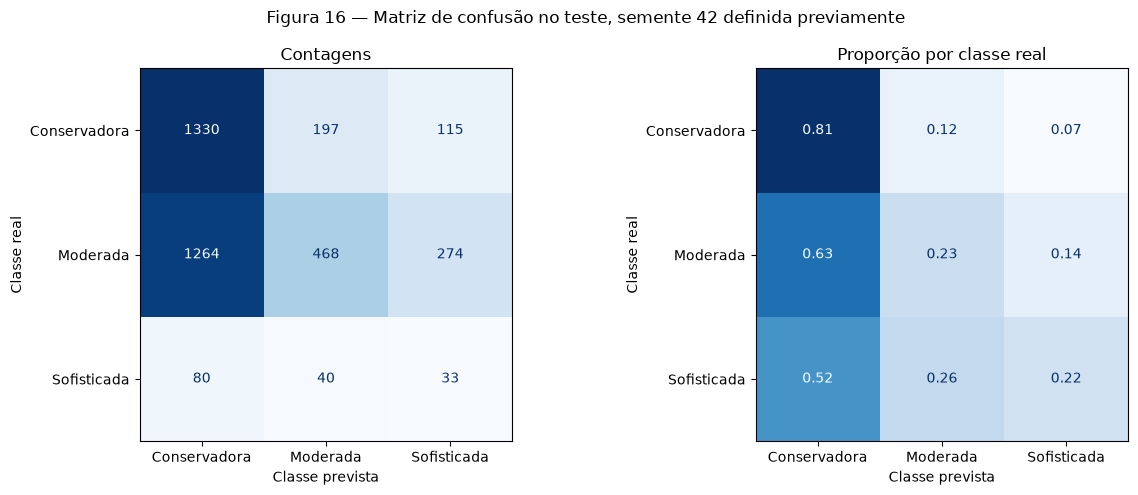

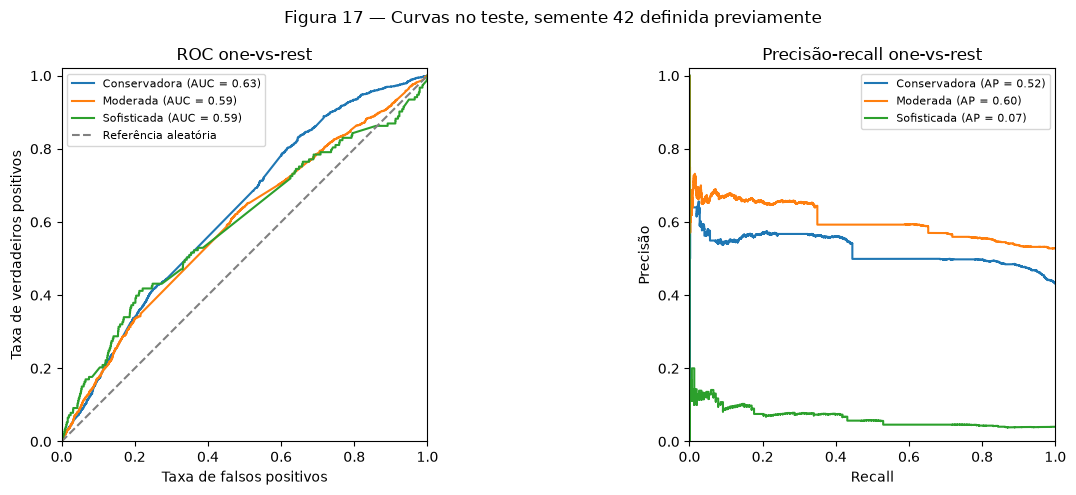

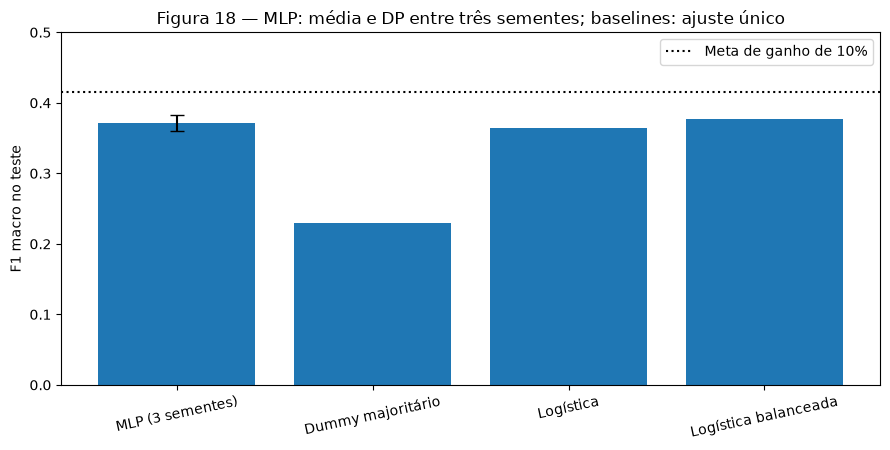

In [2]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

representative_id = f"mlp_seed{REPRESENTATIVE_SEED}"
confusion = np.asarray(final_metrics[representative_id]["confusion_matrix"])
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5))
ConfusionMatrixDisplay(confusion, display_labels=CLASS_LABELS).plot(ax=axes[0], colorbar=False, cmap="Blues", values_format="d")
ConfusionMatrixDisplay(confusion / confusion.sum(axis=1, keepdims=True), display_labels=CLASS_LABELS).plot(
    ax=axes[1], colorbar=False, cmap="Blues", values_format=".2f")
axes[0].set_title("Contagens")
axes[1].set_title("Proporção por classe real")
for ax in axes:
    ax.grid(False)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
fig.suptitle("Figura 16 — Matriz de confusão no teste, semente 42 definida previamente")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig16-confusao-teste.png", dpi=170, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
binary_test = np.eye(3, dtype=int)[y_test_encoded]
representative_probabilities = final_probabilities[representative_id]
for index, label in enumerate(CLASS_LABELS):
    areas = final_metrics[representative_id]["per_class_areas"][label]
    RocCurveDisplay.from_predictions(binary_test[:, index], representative_probabilities[:, index],
        name=label, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(binary_test[:, index], representative_probabilities[:, index],
        name=label, ax=axes[1])
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Referência aleatória")
axes[0].set(title="ROC one-vs-rest", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
axes[1].set(title="Precisão-recall one-vs-rest", xlabel="Recall", ylabel="Precisão")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=8)
fig.suptitle("Figura 17 — Curvas no teste, semente 42 definida previamente")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig17-roc-pr-teste.png", dpi=170, bbox_inches="tight")
plt.show()

f1_plot = final_comparison.loc[final_comparison["metric"] == "f1_macro"].copy()
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(f1_plot["model"], f1_plot["mean"])
network_positions = np.flatnonzero(f1_plot["n"].to_numpy() > 1)
ax.errorbar(network_positions, f1_plot.iloc[network_positions]["mean"],
            yerr=f1_plot.iloc[network_positions]["std"], fmt="none", color="black", capsize=5)
ax.axhline(1.10 * reference_test_f1, linestyle=":", color="black", label="Meta de ganho de 10%")
ax.set(ylabel="F1 macro no teste", title="Figura 18 — MLP: média e DP entre três sementes; baselines: ajuste único", ylim=(0, 0.5))
ax.tick_params(axis="x", labelrotation=12)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig18-comparacao-teste.png", dpi=170, bbox_inches="tight")
plt.show()


### 5.4. Interpretação da regra e dos resultados finais

O ajuste comparável das regras na validação escolheu fatores **(1; 1; 0,75)**
para a MLP, elevando seu F1 macro de **0,3829 para 0,4042**. Não é um corte
absoluto de probabilidade: a regra compara as pontuações multiplicadas por
esses fatores. Na validação, Conservadora prevista como Sofisticada caiu de
**113 para 58**. Sem custos monetários definidos, a escolha manteve o F1 macro;
não se afirma que ela minimize perdas financeiras.

A aplicação da mesma grade aos baselines escolheu a **logística balanceada**,
com fatores **(1; 1; 0,5)** e F1 macro de validação **0,3822**. Assim, a meta
numérica na validação passou a **0,4204**, mantendo o critério original de ganho
relativo de 10% sobre o melhor baseline validado. O valor histórico de 0,3905
referia-se às comparações anteriores com argmax. Essa mudança de referência
ocorreu antes de abrir o teste, sem escolher um baseline pelo resultado final.

Após o protocolo congelado, a rede foi retreinada no treino externo completo,
por **29 épocas**, nas sementes **42, 43 e 44**. O F1 macro no teste foi,
respectivamente, **0,3588; 0,3775; 0,3794**, resultando em **0,3719 ± 0,0114**
(média ± desvio amostral). A logística balanceada atingiu **0,3777**, a logística
sem pesos **0,3643** e o Dummy **0,2303**, todos no mesmo teste de **3.801 contas**.

O ganho relativo da média da rede contra o baseline congelado foi **−1,54%**:
**o critério de sucesso de 10% não foi atingido**. A meta no teste, calculada
pela regra prévia `1,10 × F1 do baseline no mesmo teste`, foi **0,4155**.
A diferença em módulo entre a rede e o baseline (**0,0058**) é menor que o desvio
entre sementes (**0,0114**). Não se observa vantagem consistente da rede por
essa comparação descritiva, que não constitui teste formal de significância.

A acurácia média da rede foi **0,4973 ± 0,0136**; a ROC-AUC macro OvR foi
**0,5984 ± 0,0034**, indicando separação limitada dos perfis. A PR-AUC macro
trapezoidal foi **0,3989 ± 0,0014**, e a AP macro, **0,3961 ± 0,0010**. A área
trapezoidal alta do Dummy (**0,6667**) vem da interpolação entre poucas
pontuações; sua AP macro (**0,3333**) e ROC-AUC (**0,5**) tornam explícita a
falta de discriminação desse classificador.

Para `Sofisticada`, a precisão média foi **7,34% ± 0,52 ponto percentual**, o
recall foi **15,03% ± 5,66 pontos percentuais**, e o F1 foi **0,0973 ± 0,0154**.
A AP da classe foi **0,0660 ± 0,0009**, para prevalência de **4,03%** no teste.
A classe minoritária continua difícil. Na matriz da semente ilustrativa 42,
**1.264 dos 2.006 exemplos Moderados** foram previstos como Conservadores;
esse padrão será aprofundado na análise de erros.

As Figuras 16 e 17 usam a semente 42, definida previamente, e a Figura 18
compara as médias com os baselines. Não foi escolhida a melhor semente pelo
teste. As probabilidades finais estão salvas para análises descritivas futuras,
e nenhuma regra ou configuração foi alterada em resposta a esses resultados.


A regra de decisão e o protocolo foram selecionados antes de calcular estas
métricas. As probabilidades e previsões finais estão salvas em `results/final/`
para as análises descritivas de erros. Qualquer resultado desfavorável será
reportado, sem novas escolhas de configuração orientadas por esse teste.


### Verificações da implementação

Os oito casos abaixo usam dados simulados e arquivos temporários. Conferem a
arquitetura, a perda, o dropout, as sementes, a restauração dos pesos e as regras
de decisão, sem acessar ou avaliar novamente o conjunto de teste real.


In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
import unittest

class MLPTests(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        rng = np.random.default_rng(7)
        cls.X = rng.normal(size=(180, 4)).astype(np.float32)
        cls.y = cls.X[:, :3].argmax(axis=1).astype(np.int64)
        cls.weights = np.array([0.8, 1.0, 1.4], dtype=np.float32)

    def test_architecture_returns_logits_with_expected_parameters(self):
        seed_everything(42)
        model = MLP(input_dim=16)
        logits = model(torch.zeros(5, 16))
        self.assertEqual(tuple(logits.shape), (5, 3))
        self.assertEqual(sum(p.numel() for p in model.parameters()), 3267)
        # Biases zerados produzem logits zero, não uma distribuição com soma 1.
        torch.testing.assert_close(logits, torch.zeros_like(logits))
        self.assertFalse(any(isinstance(m, torch.nn.Softmax) for m in model.modules()))

    def test_early_stopping_restores_checkpoint_and_is_reproducible(self):
        # Um delta maior que a faixa do F1 força a parada duas épocas após a primeira.
        config = TrainingConfig(
            max_epochs=10, patience=2, min_delta=1.0, batch_size=24, log_every=0,
        )
        with TemporaryDirectory() as tmp:
            checkpoint = Path(tmp) / "best.pt"
            result = fit_mlp(
                self.X[:120], self.y[:120], self.X[120:], self.y[120:],
                hidden_dims=(8, 4), class_weights=self.weights,
                config=config, checkpoint_path=checkpoint,
            )
            self.assertTrue(result.stopped_early)
            self.assertEqual(result.best_epoch, 1)
            self.assertEqual(result.epochs_run, 3)
            restored = evaluate_mlp(result.model, self.X[120:], self.y[120:], self.weights)
            self.assertAlmostEqual(restored["loss"], result.history[0]["val_loss"], places=7)
            self.assertEqual(restored["f1_macro"], result.history[0]["val_f1_macro"])
            saved_state = torch.load(checkpoint, map_location="cpu", weights_only=True)
            for name, tensor in result.model.state_dict().items():
                torch.testing.assert_close(tensor, saved_state[name], rtol=0, atol=0)

            repeated = fit_mlp(
                self.X[:120], self.y[:120], self.X[120:], self.y[120:],
                hidden_dims=(8, 4), class_weights=self.weights, config=config,
            )
            self.assertEqual(result.history, repeated.history)
            predicted_again = evaluate_mlp(repeated.model, self.X[120:], self.y[120:], self.weights)
            np.testing.assert_array_equal(restored["probabilities"], predicted_again["probabilities"])

    def test_evaluation_uses_weighted_cross_entropy(self):
        seed_everything(42)
        model = MLP(4, hidden_dims=(8, 4))
        metrics = evaluate_mlp(model, self.X, self.y, self.weights)
        expected = torch.nn.functional.cross_entropy(
            model(torch.from_numpy(self.X)), torch.from_numpy(self.y),
            weight=torch.from_numpy(self.weights),
        ).item()
        self.assertAlmostEqual(metrics["loss"], expected, places=7)
        np.testing.assert_allclose(metrics["probabilities"].sum(axis=1), 1.0, atol=1e-6)

    def test_dropout_is_active_only_during_training(self):
        seed_everything(42)
        model = MLP(4, hidden_dims=(16, 8), dropout=0.2)
        inputs = torch.from_numpy(self.X)
        model.train()
        first = model(inputs).detach().clone()
        second = model(inputs).detach().clone()
        self.assertFalse(torch.equal(first, second))
        model.eval()
        with torch.inference_mode():
            torch.testing.assert_close(model(inputs), model(inputs), rtol=0, atol=0)

        metrics = evaluate_mlp(model, self.X, self.y, self.weights)
        repeated = evaluate_mlp(model, self.X, self.y, self.weights)
        np.testing.assert_array_equal(metrics["probabilities"], repeated["probabilities"])

    def test_final_training_uses_exactly_the_fixed_epochs(self):
        config = FinalTrainingConfig(epochs=2, batch_size=24)
        first = fit_mlp_fixed_epochs(
            self.X, self.y, hidden_dims=(8, 4), class_weights=self.weights, config=config,
        )
        second = fit_mlp_fixed_epochs(
            self.X, self.y, hidden_dims=(8, 4), class_weights=self.weights, config=config,
        )
        self.assertEqual([row["epoch"] for row in first["history"]], [1, 2])
        for name, tensor in first["model"].state_dict().items():
            torch.testing.assert_close(tensor, second["model"].state_dict()[name], rtol=0, atol=0)

    def test_decision_selection_contains_argmax_and_resolves_ties(self):
        probabilities = np.array([[0.8, 0.1, 0.1], [0.1, 0.8, 0.1], [0.1, 0.1, 0.8]])
        y = np.array([0, 1, 2])
        factors, table = select_decision_rule(y, probabilities)
        self.assertEqual(len(table), 25)
        self.assertEqual(factors, [1.0, 1.0, 1.0])
        np.testing.assert_array_equal(apply_decision_rule(probabilities), y)
        self.assertEqual(table.iloc[0]["f1_macro_val"], 1.0)

    def test_probability_alignment_and_areas_for_perfect_ranking(self):
        labels = ["Conservadora", "Moderada", "Sofisticada"]
        probabilities = np.array([[0.8, 0.1, 0.1], [0.1, 0.8, 0.1], [0.1, 0.1, 0.8]])
        aligned = align_probabilities(probabilities[:, [2, 0, 1]], [labels[2], labels[0], labels[1]], labels)
        np.testing.assert_array_equal(probabilities, aligned)
        metrics = classification_metrics(np.array([0, 1, 2]), aligned, [1, 1, 1], labels)
        for value in metrics["overall"].values():
            self.assertAlmostEqual(value, 1.0)
        self.assertEqual(metrics["confusion_matrix"], np.eye(3, dtype=int).tolist())

    def test_optional_cost_constraint_is_respected(self):
        probabilities = np.array([[0.4, 0.25, 0.35], [0.2, 0.25, 0.55], [0.3, 0.5, 0.2],
                                  [0.4, 0.3, 0.3], [0.2, 0.5, 0.3], [0.3, 0.2, 0.5]])
        y = np.array([0, 0, 1, 2, 1, 2])
        factors, _ = select_decision_rule(y, probabilities, protect_conservative=True)
        control = apply_decision_rule(probabilities)
        chosen = apply_decision_rule(probabilities, factors)
        self.assertLessEqual(int(((y == 0) & (chosen == 2)).sum()),
                             int(((y == 0) & (control == 2)).sum()))


In [ ]:
verification_result = unittest.TextTestRunner(verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(MLPTests)
)
assert verification_result.wasSuccessful(), "Falha nas verificações da implementação."


test_architecture_returns_logits_with_expected_parameters (__main__.MLPTests.test_architecture_returns_logits_with_expected_parameters) ... 

ok


test_decision_selection_contains_argmax_and_resolves_ties (__main__.MLPTests.test_decision_selection_contains_argmax_and_resolves_ties) ... 

ok


test_dropout_is_active_only_during_training (__main__.MLPTests.test_dropout_is_active_only_during_training) ... 

ok


... (7 outputs left out)

ok

test_probability_alignment_and_areas_for_perfect_ranking (__main__.MLPTests.test_probability_alignment_and_areas_for_perfect_ranking) ... 

ok


----------------------------------------------------------------------
Ran 8 tests in 7.656s

OK
